<a href="https://colab.research.google.com/github/MarvleyEngine/telecom-data-mining-network-intelligence/blob/main/telco%20generated%20data%20for%20mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# ============================================================
# GHANA MOBILE TELECOM NETWORK DATASET GENERATOR
# Synthetic dataset for Data Mining / Machine Learning
# 55,000 records | 47 columns
# ============================================================

import pandas as pd
import numpy as np
from google.colab import files

# Reproducibility
np.random.seed(42)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

N = 55000

# Ghanaian regions
regions = {
    "Greater Accra": [
        "Accra Metropolitan", "Tema Metropolitan",
        "Ga East", "Ga West", "Ga South", "La Nkwantanang"
    ],
    "Ashanti": [
        "Kumasi Metropolitan", "Obuasi Municipal",
        "Ejisu Municipal", "Asokwa Municipal", "Kwadaso Municipal"
    ],
    "Eastern": [
        "New Juaben South", "Koforidua Municipal",
        "Akuapem North", "Lower Manya Krobo", "Nsawam Adoagyiri"
    ],
    "Western": [
        "Sekondi-Takoradi Metropolitan", "Tarkwa Nsuaem",
        "Ahanta West", "Prestea Huni-Valley"
    ],
    "Central": [
        "Cape Coast Metropolitan", "Kasoa",
        "Mfantsiman Municipal", "Awutu Senya", "Assin North"
    ],
    "Northern": [
        "Tamale Metropolitan", "Sagnarigu Municipal",
        "Yendi Municipal", "Tolon", "Kumbungu"
    ],
    "Volta": [
        "Ho Municipal", "Keta Municipal",
        "Kpando Municipal", "Hohoe Municipal"
    ],
    "Bono": [
        "Sunyani Municipal", "Berekum Municipal",
        "Dormaa Central", "Wenchi Municipal"
    ],
    "Upper East": [
        "Bolgatanga Municipal", "Bawku Municipal",
        "Navrongo", "Kassena Nankana"
    ],
    "Upper West": [
        "Wa Municipal", "Nandom Municipal",
        "Lawra Municipal", "Jirapa Municipal"
    ],
    "Bono East": [
        "Techiman Municipal", "Kintampo North",
        "Nkoranza South", "Atebubu Amantin"
    ],
    "Ahafo": [
        "Goaso Municipal", "Kenyasi",
        "Asunafo South", "Tano North"
    ],
    "Savannah": [
        "Damongo Municipal", "Bole", "Salaga"
    ],
    "North East": [
        "Nalerigu", "Walewale", "Garu"
    ],
    "Oti": [
        "Dambai", "Jasikan", "Nkwanta South"
    ],
    "Western North": [
        "Sefwi Wiawso", "Bibiani Anhwiaso Bekwai",
        "Juaboso", "Enchi"
    ],
}

operators = ["MTN", "Telecel", "AT"]

technologies = ["2G", "3G", "4G", "5G"]

frequency_bands = {
    "2G": ["900 MHz", "1800 MHz"],
    "3G": ["900 MHz", "2100 MHz"],
    "4G": ["800 MHz", "1800 MHz", "2100 MHz"],
    "5G": ["2600 MHz", "3500 MHz"]
}

weather_conditions = [
    "Sunny", "Cloudy", "Rain", "Heavy Rain",
    "Harmattan", "Thunderstorm"
]

# ------------------------------------------------------------
# 2. CREATE BASIC LOCATION DATA
# ------------------------------------------------------------

region_list = np.random.choice(
    list(regions.keys()),
    size=N,
    p=[
        0.16, 0.14, 0.08, 0.07, 0.07,
        0.07, 0.06, 0.05, 0.05, 0.04,
        0.04, 0.03, 0.03, 0.03, 0.02, 0.06
    ]
)

district_list = [
    np.random.choice(regions[r]) for r in region_list
]

urban_rural = []

for r in region_list:
    if r in ["Greater Accra", "Ashanti"]:
        urban_rural.append(
            np.random.choice(["Urban", "Semi-Urban", "Rural"],
                             p=[0.75, 0.20, 0.05])
        )
    else:
        urban_rural.append(
            np.random.choice(["Urban", "Semi-Urban", "Rural"],
                             p=[0.35, 0.35, 0.30])
        )

urban_rural = np.array(urban_rural)

# ------------------------------------------------------------
# 3. DATE AND TIME
# ------------------------------------------------------------

dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-31",
    freq="D"
)

date_values = np.random.choice(dates, size=N)

hours = np.random.randint(0, 24, N)
minutes = np.random.choice([0, 10, 20, 30, 40, 50], size=N)

date_strings = pd.to_datetime(date_values).strftime("%Y-%m-%d")

time_strings = [
    f"{h:02d}:{m:02d}:00"
    for h, m in zip(hours, minutes)
]

day_of_week = pd.to_datetime(date_values).day_name()

is_weekend = np.isin(
    day_of_week,
    ["Saturday", "Sunday"]
)

# Peak hours
peak_hour = (
    ((hours >= 7) & (hours <= 9)) |
    ((hours >= 12) & (hours <= 14)) |
    ((hours >= 18) & (hours <= 22))
)

# ------------------------------------------------------------
# 4. NETWORK IDENTIFIERS
# ------------------------------------------------------------

cell_ids = np.random.randint(10000, 99999, N)

site_ids = [
    f"SITE-{x:05d}"
    for x in np.random.randint(1000, 9999, N)
]

record_ids = [
    f"REC-{i:06d}"
    for i in range(1, N + 1)
]

# ------------------------------------------------------------
# 5. OPERATOR
# ------------------------------------------------------------

operator = np.random.choice(
    operators,
    size=N,
    p=[0.60, 0.25, 0.15]
)

# ------------------------------------------------------------
# 6. TECHNOLOGY
# ------------------------------------------------------------

technology = []

for urban, h in zip(urban_rural, hours):

    if urban == "Urban":
        technology.append(
            np.random.choice(
                technologies,
                p=[0.05, 0.10, 0.60, 0.25]
            )
        )

    elif urban == "Semi-Urban":
        technology.append(
            np.random.choice(
                technologies,
                p=[0.15, 0.20, 0.55, 0.10]
            )
        )

    else:
        technology.append(
            np.random.choice(
                technologies,
                p=[0.35, 0.30, 0.32, 0.03]
            )
        )

technology = np.array(technology)

frequency_band = [
    np.random.choice(frequency_bands[t])
    for t in technology
]

# ------------------------------------------------------------
# 7. GEOGRAPHIC COORDINATES
# Approximate synthetic coordinates within Ghana
# ------------------------------------------------------------

region_coords = {
    "Greater Accra": (5.6037, -0.1870),
    "Ashanti": (6.6885, -1.6244),
    "Eastern": (6.2000, -0.5000),
    "Western": (5.0000, -2.0000),
    "Central": (5.5000, -1.0000),
    "Northern": (9.4000, -0.8500),
    "Volta": (6.6000, 0.5000),
    "Bono": (7.3300, -2.3300),
    "Upper East": (10.7800, -0.8500),
    "Upper West": (10.0600, -2.5000),
    "Bono East": (7.5900, -1.9400),
    "Ahafo": (7.0000, -2.5000),
    "Savannah": (9.0800, -1.8200),
    "North East": (10.4500, -0.5200),
    "Oti": (7.8500, 0.3000),
    "Western North": (6.3000, -2.7000)
}

latitude = np.array([
    region_coords[r][0] + np.random.normal(0, 0.08)
    for r in region_list
])

longitude = np.array([
    region_coords[r][1] + np.random.normal(0, 0.08)
    for r in region_list
])

# ------------------------------------------------------------
# 8. POPULATION DENSITY
# ------------------------------------------------------------

density_base = {
    "Greater Accra": 2500,
    "Ashanti": 1500,
    "Eastern": 700,
    "Western": 650,
    "Central": 750,
    "Northern": 350,
    "Volta": 400,
    "Bono": 400,
    "Upper East": 500,
    "Upper West": 250,
    "Bono East": 300,
    "Ahafo": 250,
    "Savannah": 150,
    "North East": 150,
    "Oti": 180,
    "Western North": 250
}

population_density = np.maximum(
    20,
    [
        density_base[r] * np.random.uniform(0.5, 1.5)
        for r in region_list
    ]
)

# ------------------------------------------------------------
# 9. SUBSCRIBERS
# ------------------------------------------------------------

subscriber_count = np.maximum(
    50,
    (
        population_density *
        np.random.uniform(0.05, 0.30, N)
    ).astype(int)
)

active_users = np.maximum(
    10,
    (
        subscriber_count *
        np.random.uniform(0.45, 0.90, N)
    ).astype(int)
)

new_subscribers = np.random.poisson(
    np.maximum(subscriber_count * 0.01, 1)
)

churned_subscribers = np.random.poisson(
    np.maximum(subscriber_count * 0.005, 1)
)

# ------------------------------------------------------------
# 10. TRAFFIC
# ------------------------------------------------------------

peak_multiplier = np.where(peak_hour, 1.8, 0.75)

voice_calls = np.maximum(
    0,
    np.random.poisson(
        active_users * 0.18 * peak_multiplier
    )
)

voice_minutes = np.maximum(
    0,
    (
        voice_calls *
        np.random.gamma(2.2, 2.5, N)
    ).astype(int)
)

sms_sent = np.maximum(
    0,
    np.random.poisson(
        active_users * 0.35 * peak_multiplier
    )
)

sms_received = np.maximum(
    0,
    np.random.poisson(
        active_users * 0.40 * peak_multiplier
    )
)

data_sessions = np.maximum(
    0,
    np.random.poisson(
        active_users * 0.65 * peak_multiplier
    )
)

data_usage_mb = np.maximum(
    10,
    (
        data_sessions *
        np.random.gamma(2.5, 18, N)
    ).astype(int)
)

# ------------------------------------------------------------
# 11. NETWORK PERFORMANCE
# ------------------------------------------------------------

technology_speed = {
    "2G": (0.15, 0.05),
    "3G": (4.5, 1.2),
    "4G": (28, 8),
    "5G": (120, 35)
}

avg_download_mbps = np.array([
    max(
        0.05,
        np.random.normal(
            technology_speed[t][0],
            technology_speed[t][0] * 0.25
        )
    )
    for t in technology
])

avg_upload_mbps = np.array([
    max(
        0.02,
        np.random.normal(
            technology_speed[t][1],
            max(0.02, technology_speed[t][1] * 0.25)
        )
    )
    for t in technology
])

# Congestion increases with traffic
traffic_factor = (
    active_users /
    np.maximum(subscriber_count, 1)
)

tower_utilization_pct = np.clip(
    25 +
    traffic_factor * 45 +
    peak_hour * 18 +
    np.random.normal(0, 8, N),
    5,
    100
)

latency_ms = np.clip(
    20 +
    (tower_utilization_pct * 0.55) +
    np.random.normal(0, 8, N),
    5,
    250
)

packet_loss_pct = np.clip(
    0.5 +
    (tower_utilization_pct / 100) * 2.5 +
    np.random.normal(0, 0.7, N),
    0,
    15
)

signal_strength_dbm = np.clip(
    -65 -
    (population_density / 2000) * 15 +
    np.random.normal(0, 8, N),
    -120,
    -40
)

signal_quality_db = np.clip(
    25 +
    signal_strength_dbm / 4 +
    np.random.normal(0, 3, N),
    -10,
    30
)

# ------------------------------------------------------------
# 12. HANDOVERS / CALL QUALITY
# ------------------------------------------------------------

handover_attempts = np.maximum(
    0,
    np.random.poisson(
        active_users * 0.08
    )
)

handover_success_rate = np.clip(
    98 -
    tower_utilization_pct * 0.04 -
    packet_loss_pct * 0.3 +
    np.random.normal(0, 1.5, N),
    70,
    100
)

dropped_calls = np.maximum(
    0,
    (
        voice_calls *
        (
            0.005 +
            tower_utilization_pct / 10000 +
            packet_loss_pct / 1000
        )
    ).astype(int)
)

call_setup_success_rate = np.clip(
    99 -
    dropped_calls / np.maximum(voice_calls, 1) * 100 -
    tower_utilization_pct * 0.015 +
    np.random.normal(0, 0.5, N),
    75,
    100
)

network_availability_pct = np.clip(
    99.5 -
    np.random.exponential(0.4, N) -
    (packet_loss_pct * 0.05),
    90,
    100
)

# ------------------------------------------------------------
# 13. CONGESTION
# ------------------------------------------------------------

congestion_score = (
    tower_utilization_pct * 0.7 +
    packet_loss_pct * 2
)

congestion_level = np.where(
    congestion_score < 45,
    "Low",
    np.where(
        congestion_score < 70,
        "Medium",
        np.where(
            congestion_score < 88,
            "High",
            "Critical"
        )
    )
)

# ------------------------------------------------------------
# 14. REVENUE
# ------------------------------------------------------------

revenue_ghs = np.maximum(
    0,
    (
        voice_minutes * 0.025 +
        sms_sent * 0.03 +
        data_usage_mb * 0.008
    ) * np.random.uniform(0.75, 1.25, N)
)

# ------------------------------------------------------------
# 15. OUTAGES
# ------------------------------------------------------------

outage_probability = (
    0.015 +
    np.where(congestion_level == "Critical", 0.06, 0) +
    np.where(congestion_level == "High", 0.025, 0)
)

outage_minutes = np.where(
    np.random.random(N) < outage_probability,
    np.random.randint(5, 181, N),
    0
)

# ------------------------------------------------------------
# 16. CUSTOMER COMPLAINTS
# ------------------------------------------------------------

customer_complaints = np.maximum(
    0,
    np.random.poisson(
        1 +
        dropped_calls * 0.15 +
        packet_loss_pct * 0.35 +
        outage_minutes * 0.03
    )
)

# ------------------------------------------------------------
# 17. WEATHER
# ------------------------------------------------------------

weather_condition = np.random.choice(
    weather_conditions,
    size=N,
    p=[0.35, 0.25, 0.18, 0.08, 0.10, 0.04]
)

# Weather impact
weather_bad = np.isin(
    weather_condition,
    ["Heavy Rain", "Thunderstorm"]
)

packet_loss_pct = np.clip(
    packet_loss_pct + weather_bad * np.random.uniform(0.5, 3.0, N),
    0,
    20
)

# ------------------------------------------------------------
# 18. CUSTOMER SATISFACTION
# ------------------------------------------------------------

customer_satisfaction = np.clip(
    8.5
    - (latency_ms / 100)
    - (packet_loss_pct * 0.10)
    - (customer_complaints * 0.04)
    - (outage_minutes * 0.008)
    + (avg_download_mbps / 100)
    + np.random.normal(0, 0.5, N),
    1,
    10
)

customer_satisfaction = np.round(
    customer_satisfaction,
    2
)

# ------------------------------------------------------------
# 19. CHURN RISK
# ------------------------------------------------------------

churn_score = (
    0.35 * (10 - customer_satisfaction) +
    0.02 * latency_ms +
    0.35 * packet_loss_pct +
    0.02 * outage_minutes +
    0.20 * customer_complaints
)

churn_probability = 1 / (
    1 + np.exp(-(churn_score - 4))
)

churn_risk = np.where(
    churn_probability >= 0.70,
    "High",
    np.where(
        churn_probability >= 0.40,
        "Medium",
        "Low"
    )
)

# ------------------------------------------------------------
# 20. NETWORK PERFORMANCE SCORE
# ------------------------------------------------------------

network_performance_score = np.clip(
    100
    - latency_ms * 0.12
    - packet_loss_pct * 1.5
    - tower_utilization_pct * 0.08
    + avg_download_mbps * 0.08
    - outage_minutes * 0.08,
    0,
    100
)

network_performance_score = np.round(
    network_performance_score,
    2
)

# ------------------------------------------------------------
# 21. BUILD DATAFRAME
# ------------------------------------------------------------

df = pd.DataFrame({
    "record_id": record_ids,
    "date": date_strings,
    "time": time_strings,
    "region": region_list,
    "district": district_list,
    "cell_id": cell_ids,
    "site_id": site_ids,
    "operator": operator,
    "technology": technology,
    "frequency_band": frequency_band,
    "latitude": np.round(latitude, 6),
    "longitude": np.round(longitude, 6),
    "population_density": np.round(population_density, 2),
    "urban_rural": urban_rural,
    "subscriber_count": subscriber_count,
    "active_users": active_users,
    "new_subscribers": new_subscribers,
    "churned_subscribers": churned_subscribers,
    "voice_calls": voice_calls,
    "voice_minutes": voice_minutes,
    "sms_sent": sms_sent,
    "sms_received": sms_received,
    "data_sessions": data_sessions,
    "data_usage_mb": data_usage_mb,
    "avg_download_mbps": np.round(avg_download_mbps, 2),
    "avg_upload_mbps": np.round(avg_upload_mbps, 2),
    "latency_ms": np.round(latency_ms, 2),
    "packet_loss_pct": np.round(packet_loss_pct, 3),
    "signal_strength_dbm": np.round(signal_strength_dbm, 2),
    "signal_quality_db": np.round(signal_quality_db, 2),
    "handover_attempts": handover_attempts,
    "handover_success_rate": np.round(handover_success_rate, 2),
    "dropped_calls": dropped_calls,
    "call_setup_success_rate": np.round(call_setup_success_rate, 2),
    "network_availability_pct": np.round(network_availability_pct, 2),
    "tower_utilization_pct": np.round(tower_utilization_pct, 2),
    "congestion_level": congestion_level,
    "revenue_ghs": np.round(revenue_ghs, 2),
    "customer_complaints": customer_complaints,
    "outage_minutes": outage_minutes,
    "weather_condition": weather_condition,
    "day_of_week": day_of_week,
    "is_weekend": is_weekend,
    "peak_hour": peak_hour,
    "customer_satisfaction": customer_satisfaction,
    "churn_risk": churn_risk,
    "network_performance_score": network_performance_score
})

# ------------------------------------------------------------
# 22. SAVE CSV
# ------------------------------------------------------------

filename = "ghana_mobile_telecom_network_55000.csv"

df.to_csv(
    filename,
    index=False
)

# ------------------------------------------------------------
# 23. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("GHANA MOBILE TELECOM NETWORK DATASET CREATED")
print("=" * 70)

print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"File:    {filename}")

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nOperator distribution:")
print(df["operator"].value_counts())

print("\nTechnology distribution:")
print(df["technology"].value_counts())

print("\nRegion distribution:")
print(df["region"].value_counts())

# ------------------------------------------------------------
# 24. DOWNLOAD CSV
# ------------------------------------------------------------

files.download(filename)

print("\nCSV download should now begin automatically.")

GHANA MOBILE TELECOM NETWORK DATASET CREATED
Rows:    55,000
Columns: 47
File:    ghana_mobile_telecom_network_55000.csv

First 5 records:


,record_id,date,time,region,district,cell_id,site_id,operator,technology,frequency_band,...,revenue_ghs,customer_complaints,outage_minutes,weather_condition,day_of_week,is_weekend,peak_hour,customer_satisfaction,churn_risk,network_performance_score
0,REC-000001,2025-12-11,08:20:00,Eastern,Nsawam Adoagyiri,14676,SITE-08846,AT,3G,2100 MHz,...,22.14,2,0,Rain,Thursday,False,True,7.33,Medium,79.31
1,REC-000002,2025-07-11,07:40:00,Western North,Enchi,44731,SITE-06435,MTN,4G,2100 MHz,...,57.18,0,0,Cloudy,Friday,False,True,7.59,Low,85.37
2,REC-000003,2025-10-23,10:50:00,Upper East,Navrongo,57971,SITE-04315,MTN,4G,2100 MHz,...,4.46,1,0,Sunny,Thursday,False,False,8.34,Low,90.33
3,REC-000004,2025-05-04,20:10:00,Volta,Kpando Municipal,71429,SITE-04911,Telecel,2G,1800 MHz,...,10.18,2,0,Sunny,Sunday,True,True,8.92,Low,81.55
4,REC-000005,2025-02-08,21:30:00,Greater Accra,Ga East,73861,SITE-07030,AT,4G,1800 MHz,...,169.77,3,0,Sunny,Saturday,True,True,7.71,Medium,83.27



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 47 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   record_id                  55000 non-null  object 
 1   date                       55000 non-null  object 
 2   time                       55000 non-null  object 
 3   region                     55000 non-null  object 
 4   district                   55000 non-null  object 
 5   cell_id                    55000 non-null  int64  
 6   site_id                    55000 non-null  object 
 7   operator                   55000 non-null  object 
 8   technology                 55000 non-null  object 
 9   frequency_band             55000 non-null  object 
 10  latitude                   55000 non-null  float64
 11  longitude                  55000 non-null  float64
 12  population_density         55000 non-null  float64
 13  urban_rural             

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


CSV download should now begin automatically.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [3]:
df.head()



,record_id,date,time,region,district,cell_id,site_id,operator,technology,frequency_band,...,revenue_ghs,customer_complaints,outage_minutes,weather_condition,day_of_week,is_weekend,peak_hour,customer_satisfaction,churn_risk,network_performance_score
0,REC-000001,2025-12-11,08:20:00,Eastern,Nsawam Adoagyiri,14676,SITE-08846,AT,3G,2100 MHz,...,22.14,2,0,Rain,Thursday,False,True,7.33,Medium,79.31
1,REC-000002,2025-07-11,07:40:00,Western North,Enchi,44731,SITE-06435,MTN,4G,2100 MHz,...,57.18,0,0,Cloudy,Friday,False,True,7.59,Low,85.37
2,REC-000003,2025-10-23,10:50:00,Upper East,Navrongo,57971,SITE-04315,MTN,4G,2100 MHz,...,4.46,1,0,Sunny,Thursday,False,False,8.34,Low,90.33
3,REC-000004,2025-05-04,20:10:00,Volta,Kpando Municipal,71429,SITE-04911,Telecel,2G,1800 MHz,...,10.18,2,0,Sunny,Sunday,True,True,8.92,Low,81.55
4,REC-000005,2025-02-08,21:30:00,Greater Accra,Ga East,73861,SITE-07030,AT,4G,1800 MHz,...,169.77,3,0,Sunny,Saturday,True,True,7.71,Medium,83.27


In [4]:
df.describe()


,cell_id,latitude,longitude,population_density,subscriber_count,active_users,new_subscribers,churned_subscribers,voice_calls,voice_minutes,...,handover_success_rate,dropped_calls,call_setup_success_rate,network_availability_pct,tower_utilization_pct,revenue_ghs,customer_complaints,outage_minutes,customer_satisfaction,network_performance_score
count,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,...,55000.000000,55000.000000,55000.000000,55000.000000,55000.00000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000
mean,54988.695636,7.054760,-1.172884,913.304822,165.187509,110.850091,1.858836,1.256509,24.589945,133.414236,...,94.844975,0.098109,97.957897,98.996540,63.43970,36.429197,1.786545,1.445345,7.976978,87.467956
std,25945.849091,1.688933,0.938993,868.728179,172.962687,120.428854,2.085859,1.296995,31.300780,217.616337,...,1.638863,0.383447,0.647100,0.399531,13.31951,57.760877,1.419885,13.136104,0.676038,4.467911
min,10001.000000,4.739905,-2.977316,75.020000,50.000000,22.000000,0.000000,0.000000,0.000000,0.000000,...,88.160000,0.000000,94.730000,94.840000,15.14000,0.410000,0.000000,0.000000,4.500000,64.920000
25%,32627.500000,5.645057,-1.951286,302.522500,50.000000,37.000000,0.000000,0.000000,7.000000,26.000000,...,93.750000,0.000000,97.600000,98.840000,53.74750,8.310000,1.000000,0.000000,7.520000,84.530000
50%,55030.000000,6.614713,-0.997405,537.330000,90.000000,60.000000,1.000000,1.000000,13.000000,61.000000,...,94.850000,0.000000,98.010000,99.120000,63.26000,17.520000,2.000000,0.000000,7.930000,87.050000
75%,77406.250000,7.634714,-0.396560,1267.590000,201.000000,134.000000,3.000000,2.000000,29.000000,145.000000,...,95.940000,0.000000,98.390000,99.280000,72.95000,39.410000,3.000000,0.000000,8.390000,89.850000
max,99996.000000,11.049542,0.745394,3749.920000,1106.000000,923.000000,18.000000,15.000000,312.000000,4768.000000,...,100.000000,5.000000,100.000000,99.500000,100.00000,1661.380000,16.000000,180.000000,10.000000,100.000000


In [5]:
df.shape

(55000, 47)

In [6]:
df.columns

Index(['record_id', 'date', 'time', 'region', 'district', 'cell_id', 'site_id',
       'operator', 'technology', 'frequency_band', 'latitude', 'longitude',
       'population_density', 'urban_rural', 'subscriber_count', 'active_users',
       'new_subscribers', 'churned_subscribers', 'voice_calls',
       'voice_minutes', 'sms_sent', 'sms_received', 'data_sessions',
       'data_usage_mb', 'avg_download_mbps', 'avg_upload_mbps', 'latency_ms',
       'packet_loss_pct', 'signal_strength_dbm', 'signal_quality_db',
       'handover_attempts', 'handover_success_rate', 'dropped_calls',
       'call_setup_success_rate', 'network_availability_pct',
       'tower_utilization_pct', 'congestion_level', 'revenue_ghs',
       'customer_complaints', 'outage_minutes', 'weather_condition',
       'day_of_week', 'is_weekend', 'peak_hour', 'customer_satisfaction',
       'churn_risk', 'network_performance_score'],
      dtype='object')

In [7]:
df.sample

<bound method NDFrame.sample of         record_id        date      time         region          district  \
0      REC-000001  2025-12-11  08:20:00        Eastern  Nsawam Adoagyiri   
1      REC-000002  2025-07-11  07:40:00  Western North             Enchi   
2      REC-000003  2025-10-23  10:50:00     Upper East          Navrongo   
3      REC-000004  2025-05-04  20:10:00          Volta  Kpando Municipal   
4      REC-000005  2025-02-08  21:30:00  Greater Accra           Ga East   
...           ...         ...       ...            ...               ...   
54995  REC-054996  2025-03-21  18:40:00       Northern   Yendi Municipal   
54996  REC-054997  2025-01-14  03:50:00     Upper East   Bawku Municipal   
54997  REC-054998  2025-03-19  04:40:00      Bono East    Kintampo North   
54998  REC-054999  2025-04-08  03:50:00          Volta  Kpando Municipal   
54999  REC-055000  2025-11-23  07:30:00      Bono East    Kintampo North   

       cell_id     site_id operator technology frequency_band  ...  \
0        14676  SITE-08846       AT         3G       2100 MHz  ...   
1        44731  SITE-06435      MTN         4G       2100 MHz  ...   
2        57971  SITE-04315      MTN         4G       2100 MHz  ...   
3        71429  SITE-04911  Telecel         2G       1800 MHz  ...   
4        73861  SITE-07030       AT         4G       1800 MHz  ...   
...        ...         ...      ...        ...            ...  ...   
54995    52911  SITE-01939       AT         3G        900 MHz  ...   
54996    96312  SITE-08212      MTN         4G       1800 MHz  ...   
54997    10255  SITE-08141  Telecel         3G       2100 MHz  ...   
54998    33514  SITE-04902      MTN         4G       2100 MHz  ...   
54999    38468  SITE-05098      MTN         4G       1800 MHz  ...   

       revenue_ghs  customer_complaints  outage_minutes weather_condition  \
0            22.14                    2               0              Rain   
1            57.18                    0               0            Cloudy   
2             4.46                    1               0             Sunny   
3            10.18                    2               0             Sunny   
4           169.77                    3               0             Sunny   
...            ...                  ...             ...               ...   
54995        20.76                    3               0            Cloudy   
54996        10.39                    1               0             Sunny   
54997        16.38                    4               0             Sunny   
54998        11.05                    0               0             Sunny   
54999         8.79                    4               0            Cloudy   

       day_of_week  is_weekend  peak_hour  customer_satisfaction  churn_risk  \
0         Thursday       False       True                   7.33      Medium   
1           Friday       False       True                   7.59         Low   
2         Thursday       False      False                   8.34         Low   
3           Sunday        True       True                   8.92         Low   
4         Saturday        True       True                   7.71      Medium   
...            ...         ...        ...                    ...         ...   
54995       Friday       False       True                   7.19         Low   
54996      Tuesday       False      False                   7.68         Low   
54997    Wednesday       False      False                   6.75      Medium   
54998      Tuesday       False      False                   7.74         Low   
54999       Sunday        True       True                   8.86         Low   

       network_performance_score  
0                          79.31  
1                          85.37  
2                          90.33  
3                          81.55  
4                          83.27  
...                          ...  
54995                      84.45  
54996                      90.21  
54997        

In [8]:
df.select_dtypes(include="object").nunique()

,0
record_id,55000
date,365
time,144
region,16
district,67
site_id,8979
operator,3
technology,4
frequency_band,6
urban_rural,3


In [9]:
for col in df.select_dtypes(include="object"):
    print("\n", col)
    print(df[col].value_counts())


 record_id
record_id
REC-055000    1
REC-000001    1
REC-000002    1
REC-000003    1
REC-000004    1
             ..
REC-000013    1
REC-000012    1
REC-000011    1
REC-000010    1
REC-000009    1
Name: count, Length: 55000, dtype: int64

 date
date
2025-04-12    187
2025-01-02    183
2025-08-01    181
2025-04-22    178
2025-07-18    176
             ... 
2025-12-27    125
2025-01-24    125
2025-03-31    122
2025-11-07    121
2025-01-08    119
Name: count, Length: 365, dtype: int64

 time
time
01:20:00    431
23:30:00    425
02:00:00    425
09:10:00    418
07:20:00    418
           ... 
05:50:00    346
11:50:00    339
11:30:00    339
09:20:00    335
13:10:00    311
Name: count, Length: 144, dtype: int64

 region
region
Greater Accra    8780
Ashanti          7749
Eastern          4399
Central          3874
Western          3860
Northern         3801
Volta            3368
Western North    3263
Bono             2810
Upper East       2691
Upper West       2203
Bono East        2175
Savan

In [10]:
df.isnull().sum()

,0
record_id,0
date,0
time,0
region,0
district,0
cell_id,0
site_id,0
operator,0
technology,0
frequency_band,0


In [11]:
df.isnull().mean() * 100

,0
record_id,0.0
date,0.0
time,0.0
region,0.0
district,0.0
cell_id,0.0
site_id,0.0
operator,0.0
technology,0.0
frequency_band,0.0


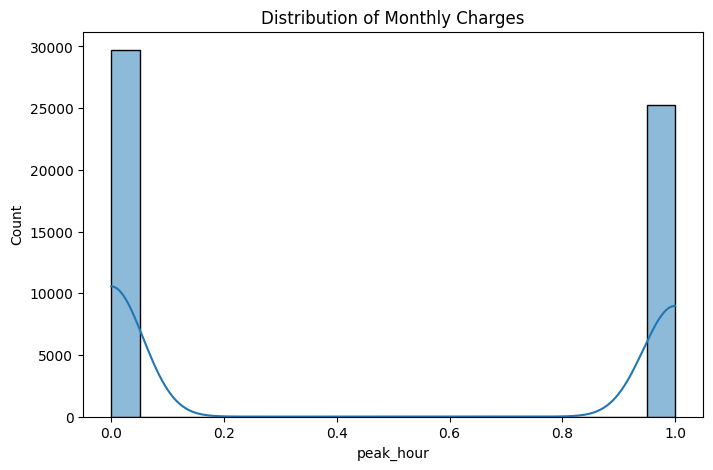

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(df["peak_hour"], kde=True)

plt.title("Distribution of Monthly Charges")
plt.show()

In [13]:
import duckdb

In [14]:
result = duckdb.sql("""
    SELECT *
    FROM df
""")

result

┌────────────┬────────────┬──────────┬───────────────┬─────────────────────┬─────────┬────────────┬──────────┬────────────┬────────────────┬───────────┬───────────┬────────────────────┬─────────────┬──────────────────┬──────────────┬─────────────────┬─────────────────────┬─────────────┬───────────────┬──────────┬──────────────┬───────────────┬───────────────┬───────────────────┬─────────────────┬────────────┬─────────────────┬─────────────────────┬───────────────────┬───────────────────┬───────────────────────┬───────────────┬─────────────────────────┬──────────────────────────┬───────────────────────┬──────────────────┬─────────────┬─────────────────────┬────────────────┬───────────────────┬─────────────┬────────────┬───────────┬───────────────────────┬────────────┬───────────────────────────┐
│ record_id  │    date    │   time   │    region     │      district       │ cell_id │  site_id   │ operator │ technology │ frequency_band │ latitude  │ longitude │ population_density │ urban_ru

In [15]:
duckdb.sql(""" select record_id, sum(data_usage_mb) usage from result group by record_id order by usage desc limit 10""" )

┌────────────┬────────┐
│ record_id  │ usage  │
│  varchar   │ int128 │
├────────────┼────────┤
│ REC-010115 │ 191218 │
│ REC-031340 │ 136435 │
│ REC-025495 │ 132694 │
│ REC-001711 │ 132154 │
│ REC-031946 │ 129349 │
│ REC-032060 │ 120968 │
│ REC-004389 │ 117887 │
│ REC-030116 │ 109352 │
│ REC-040284 │ 102143 │
│ REC-048966 │  94999 │
├────────────┴────────┤
│ 10 rows   2 columns │
└─────────────────────┘

In [16]:
duckdb.sql(""" select record_id, sum(revenue_ghs) usage from result group by record_id order by usage desc limit 10""" )

┌────────────┬─────────┐
│ record_id  │  usage  │
│  varchar   │ double  │
├────────────┼─────────┤
│ REC-010115 │ 1661.38 │
│ REC-001711 │ 1460.53 │
│ REC-025495 │  1200.0 │
│ REC-031340 │ 1088.64 │
│ REC-030116 │ 1053.09 │
│ REC-032060 │ 1008.76 │
│ REC-031946 │  971.82 │
│ REC-038897 │  881.18 │
│ REC-040284 │  861.96 │
│ REC-036801 │  830.85 │
├────────────┴─────────┤
│ 10 rows    2 columns │
└──────────────────────┘

In [17]:
num_cols = df.select_dtypes(include=np.number).columns

cat_cols = df.select_dtypes(include="object").columns

print("Numerical:")
print(num_cols)

print("\nCategorical:")
print(cat_cols)

Numerical:
Index(['cell_id', 'latitude', 'longitude', 'population_density',
       'subscriber_count', 'active_users', 'new_subscribers',
       'churned_subscribers', 'voice_calls', 'voice_minutes', 'sms_sent',
       'sms_received', 'data_sessions', 'data_usage_mb', 'avg_download_mbps',
       'avg_upload_mbps', 'latency_ms', 'packet_loss_pct',
       'signal_strength_dbm', 'signal_quality_db', 'handover_attempts',
       'handover_success_rate', 'dropped_calls', 'call_setup_success_rate',
       'network_availability_pct', 'tower_utilization_pct', 'revenue_ghs',
       'customer_complaints', 'outage_minutes', 'customer_satisfaction',
       'network_performance_score'],
      dtype='object')

Categorical:
Index(['record_id', 'date', 'time', 'region', 'district', 'site_id',
       'operator', 'technology', 'frequency_band', 'urban_rural',
       'congestion_level', 'weather_condition', 'day_of_week', 'churn_risk'],
      dtype='object')


In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
for col in cat_cols:
    print("\n" + "="*40)
    print(col)
    print(df[col].value_counts())


record_id
record_id
REC-055000    1
REC-000001    1
REC-000002    1
REC-000003    1
REC-000004    1
             ..
REC-000013    1
REC-000012    1
REC-000011    1
REC-000010    1
REC-000009    1
Name: count, Length: 55000, dtype: int64

date
date
2025-04-12    187
2025-01-02    183
2025-08-01    181
2025-04-22    178
2025-07-18    176
             ... 
2025-12-27    125
2025-01-24    125
2025-03-31    122
2025-11-07    121
2025-01-08    119
Name: count, Length: 365, dtype: int64

time
time
01:20:00    431
23:30:00    425
02:00:00    425
09:10:00    418
07:20:00    418
           ... 
05:50:00    346
11:50:00    339
11:30:00    339
09:20:00    335
13:10:00    311
Name: count, Length: 144, dtype: int64

region
region
Greater Accra    8780
Ashanti          7749
Eastern          4399
Central          3874
Western          3860
Northern         3801
Volta            3368
Western North    3263
Bono             2810
Upper East       2691
Upper West       2203
Bono East        2175
Savannah 

In [20]:
num_cols = df.select_dtypes(include=np.number).columns

len(num_cols), num_cols.tolist()


(31,
 ['cell_id',
  'latitude',
  'longitude',
  'population_density',
  'subscriber_count',
  'active_users',
  'new_subscribers',
  'churned_subscribers',
  'voice_calls',
  'voice_minutes',
  'sms_sent',
  'sms_received',
  'data_sessions',
  'data_usage_mb',
  'avg_download_mbps',
  'avg_upload_mbps',
  'latency_ms',
  'packet_loss_pct',
  'signal_strength_dbm',
  'signal_quality_db',
  'handover_attempts',
  'handover_success_rate',
  'dropped_calls',
  'call_setup_success_rate',
  'network_availability_pct',
  'tower_utilization_pct',
  'revenue_ghs',
  'customer_complaints',
  'outage_minutes',
  'customer_satisfaction',
  'network_performance_score'])

In [21]:
key_numeric = [
    "subscriber_count",
    "active_users",
    "new_subscribers",
    "churned_subscribers",
    "voice_minutes",
    "data_usage_mb",
    "avg_download_mbps",
    "latency_ms",
    "packet_loss_pct",
    "revenue_ghs",
    "customer_complaints",
    "customer_satisfaction",
    "churn_risk",
    "network_performance_score"
]

In [22]:
df[key_numeric].describe().T

,count,mean,std,min,25%,50%,75%,max
subscriber_count,55000.0,165.187509,172.962687,50.00,50.000,90.000,201.0000,1106.000
active_users,55000.0,110.850091,120.428854,22.00,37.000,60.000,134.0000,923.000
new_subscribers,55000.0,1.858836,2.085859,0.00,0.000,1.000,3.0000,18.000
churned_subscribers,55000.0,1.256509,1.296995,0.00,0.000,1.000,2.0000,15.000
voice_minutes,55000.0,133.414236,217.616337,0.00,26.000,61.000,145.0000,4768.000
data_usage_mb,55000.0,3963.428491,6504.111122,10.00,845.000,1851.000,4263.0000,191218.000
avg_download_mbps,55000.0,33.925259,40.331331,0.05,4.750,25.120,34.3025,229.910
latency_ms,55000.0,54.889301,10.842681,9.41,47.530,54.850,62.2800,99.690
packet_loss_pct,55000.0,2.300305,0.995700,0.00,1.638,2.202,2.8230,6.904
revenue_ghs,55000.0,36.429197,57.760877,0.41,8.310,17.520,39.4100,1661.380


In [23]:
df['subscriber_count'].value_counts().head(10)

,count
subscriber_count,
50,15972
51,398
52,379
53,374
59,363
54,361
57,353
55,349
64,333


In [24]:
Q1 = df['subscriber_count'].quantile(0.25)
Q3 = df['subscriber_count'].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Upper outlier threshold:", upper_limit)

IQR: 151.0
Upper outlier threshold: 427.5


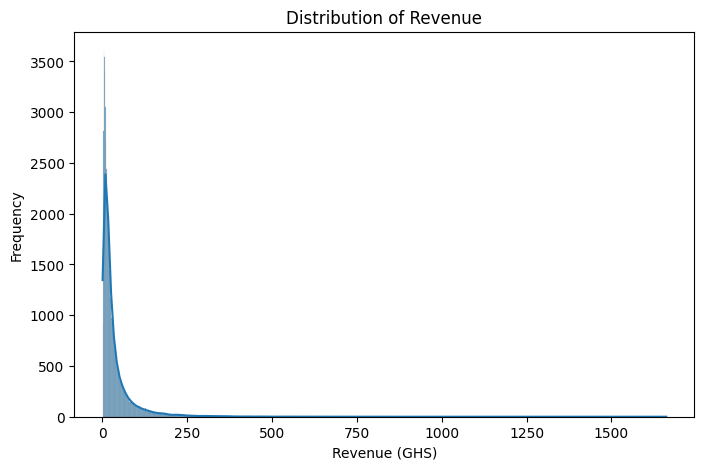

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(df["revenue_ghs"], kde=True)

plt.title("Distribution of Revenue")
plt.xlabel("Revenue (GHS)")
plt.ylabel("Frequency")

plt.show()

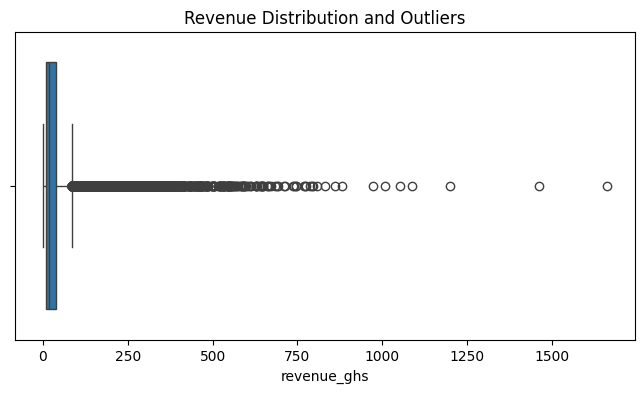

In [26]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df["revenue_ghs"])

plt.title("Revenue Distribution and Outliers")

plt.show()

In [27]:
df["operator"].value_counts()

,count
operator,
MTN,33079
Telecel,13805
AT,8116


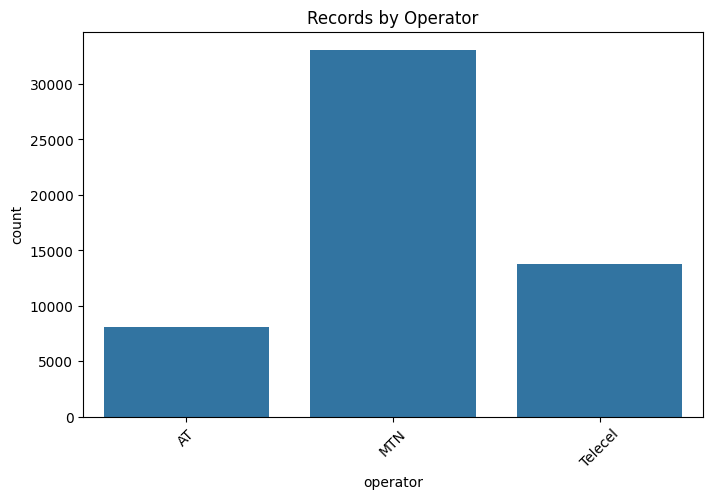

In [28]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="operator")

plt.title("Records by Operator")
plt.xticks(rotation=45)

plt.show()

In [29]:
df.groupby("operator")["revenue_ghs"].sum().sort_values(ascending=False)

,revenue_ghs
operator,
MTN,1203504.41
Telecel,501619.34
AT,298482.10


In [30]:
dd = df.groupby("operator")["revenue_ghs"].sum().sort_values(ascending=False)
dd.describe()

,revenue_ghs
count,3.000000e+00
mean,6.678686e+05
std,4.748636e+05
min,2.984821e+05
25%,4.000507e+05
50%,5.016193e+05
75%,8.525619e+05
max,1.203504e+06


In [31]:
df["churn_risk"].describe()

,churn_risk
count,55000
unique,3
top,Low
freq,45388


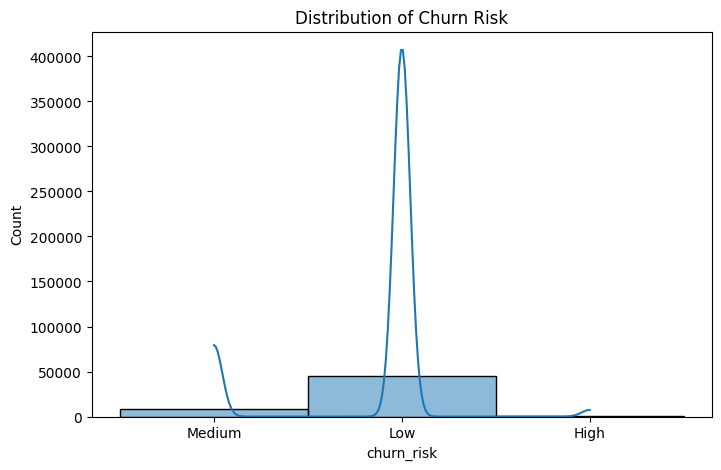

In [32]:
plt.figure(figsize=(8,5))

sns.histplot(df["churn_risk"], kde=True)

plt.title("Distribution of Churn Risk")

plt.show()

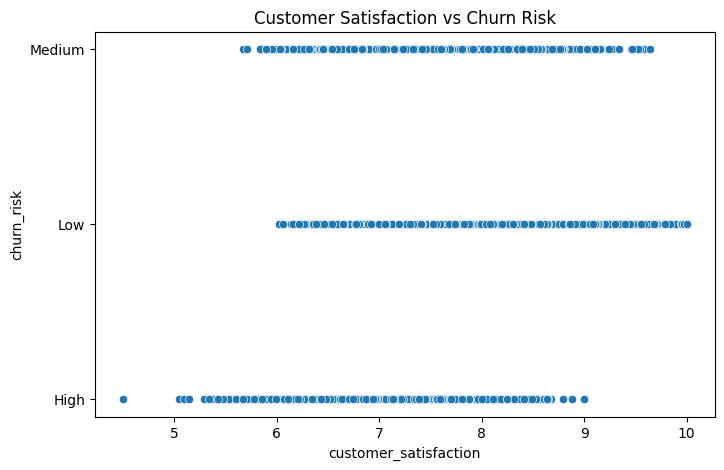

In [33]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="customer_satisfaction",
    y="churn_risk"
)

plt.title("Customer Satisfaction vs Churn Risk")

plt.show()

In [34]:
df.groupby("region")["revenue_ghs"].sum().sort_values(ascending=False)

,revenue_ghs
region,
Greater Accra,854652.26
Ashanti,440443.49
Eastern,118903.11
Central,109737.83
Western,97304.39
Northern,58461.42
Volta,55334.55
Upper East,53853.58
Bono,47642.33


In [35]:
aa = df.groupby("region")["revenue_ghs"].sum().sort_values(ascending=False)
aa.describe()

,revenue_ghs
count,16.000000
mean,125225.365625
std,219905.770989
min,12482.890000
25%,25466.395000
50%,50747.955000
75%,100412.750000
max,854652.260000


In [36]:
aa = df.groupby("customer_complaints")["customer_satisfaction"].sum().sort_values(ascending=False)
aa.describe()

,customer_satisfaction
count,15.000000
mean,29248.920000
std,45593.587014
min,7.050000
25%,103.675000
50%,1341.440000
75%,48139.105000
max,131244.180000


In [37]:
df.groupby("customer_complaints")["customer_satisfaction"].sum().sort_values(ascending=False)

,customer_satisfaction
customer_complaints,
1,131244.18
2,113401.15
0,80300.40
3,65792.25
4,30485.96
5,11284.04
6,3850.10
7,1341.44
8,541.45


In [38]:
aa = df.groupby("data_usage_mb")["revenue_ghs"].sum().sort_values(ascending=False)
aa.describe()

,revenue_ghs
count,12781.000000
mean,156.764404
std,92.884459
min,0.450000
25%,94.790000
50%,141.000000
75%,196.260000
max,1661.380000


In [39]:
display(aa)

,revenue_ghs
data_usage_mb,
191218,1661.38
132154,1460.53
132694,1200.00
136435,1088.64
109352,1053.09
...,...
30,0.69
21,0.55
26,0.53


In [40]:
df["activity_rate"] = (
    df["active_users"] / df["subscriber_count"]
) * 100

display(df)

,record_id,date,time,region,district,cell_id,site_id,operator,technology,frequency_band,...,customer_complaints,outage_minutes,weather_condition,day_of_week,is_weekend,peak_hour,customer_satisfaction,churn_risk,network_performance_score,activity_rate
0,REC-000001,2025-12-11,08:20:00,Eastern,Nsawam Adoagyiri,14676,SITE-08846,AT,3G,2100 MHz,...,2,0,Rain,Thursday,False,True,7.33,Medium,79.31,76.388889
1,REC-000002,2025-07-11,07:40:00,Western North,Enchi,44731,SITE-06435,MTN,4G,2100 MHz,...,0,0,Cloudy,Friday,False,True,7.59,Low,85.37,78.461538
2,REC-000003,2025-10-23,10:50:00,Upper East,Navrongo,57971,SITE-04315,MTN,4G,2100 MHz,...,1,0,Sunny,Thursday,False,False,8.34,Low,90.33,53.947368
3,REC-000004,2025-05-04,20:10:00,Volta,Kpando Municipal,71429,SITE-04911,Telecel,2G,1800 MHz,...,2,0,Sunny,Sunday,True,True,8.92,Low,81.55,87.272727
4,REC-000005,2025-02-08,21:30:00,Greater Accra,Ga East,73861,SITE-07030,AT,4G,1800 MHz,...,3,0,Sunny,Saturday,True,True,7.71,Medium,83.27,67.311072
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54995,REC-054996,2025-03-21,18:40:00,Northern,Yendi Municipal,52911,SITE-01939,AT,3G,900 MHz,...,3,0,Cloudy,Friday,False,True,7.19,Low,84.45,68.000000
54996,REC-054997,2025-01-14,03:50:00,Upper East,Bawku Municipal,96312,SITE-08212,MTN,4G,1800 MHz,...,1,0,Sunny,Tuesday,False,False,7.68,Low,90.21,58.620690
54997,REC-054998,2025-03-19,04:40:00,Bono East,Kintampo North,10255,SITE-08141,Telecel,3G,2100 MHz,...,4,0,Sunny,Wednesday,False,False,6.75,Medium,85.88,78.787879
54998,REC-054999,2025-04-08,03:50:00,Volta,Kpando Municipal,33514,SITE-04902,MTN,4G,2100 MHz,...,0,0,Sunny,Tuesday,False,False,7.74,Low,90.84,48.000000


In [41]:
df["churn_rate"] = (
    df["churned_subscribers"] / df["subscriber_count"]
) * 100
display(df)

,record_id,date,time,region,district,cell_id,site_id,operator,technology,frequency_band,...,outage_minutes,weather_condition,day_of_week,is_weekend,peak_hour,customer_satisfaction,churn_risk,network_performance_score,activity_rate,churn_rate
0,REC-000001,2025-12-11,08:20:00,Eastern,Nsawam Adoagyiri,14676,SITE-08846,AT,3G,2100 MHz,...,0,Rain,Thursday,False,True,7.33,Medium,79.31,76.388889,1.388889
1,REC-000002,2025-07-11,07:40:00,Western North,Enchi,44731,SITE-06435,MTN,4G,2100 MHz,...,0,Cloudy,Friday,False,True,7.59,Low,85.37,78.461538,0.000000
2,REC-000003,2025-10-23,10:50:00,Upper East,Navrongo,57971,SITE-04315,MTN,4G,2100 MHz,...,0,Sunny,Thursday,False,False,8.34,Low,90.33,53.947368,0.000000
3,REC-000004,2025-05-04,20:10:00,Volta,Kpando Municipal,71429,SITE-04911,Telecel,2G,1800 MHz,...,0,Sunny,Sunday,True,True,8.92,Low,81.55,87.272727,3.636364
4,REC-000005,2025-02-08,21:30:00,Greater Accra,Ga East,73861,SITE-07030,AT,4G,1800 MHz,...,0,Sunny,Saturday,True,True,7.71,Medium,83.27,67.311072,0.351494
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54995,REC-054996,2025-03-21,18:40:00,Northern,Yendi Municipal,52911,SITE-01939,AT,3G,900 MHz,...,0,Cloudy,Friday,False,True,7.19,Low,84.45,68.000000,8.000000
54996,REC-054997,2025-01-14,03:50:00,Upper East,Bawku Municipal,96312,SITE-08212,MTN,4G,1800 MHz,...,0,Sunny,Tuesday,False,False,7.68,Low,90.21,58.620690,0.985222
54997,REC-054998,2025-03-19,04:40:00,Bono East,Kintampo North,10255,SITE-08141,Telecel,3G,2100 MHz,...,0,Sunny,Wednesday,False,False,6.75,Medium,85.88,78.787879,1.515152
54998,REC-054999,2025-04-08,03:50:00,Volta,Kpando Municipal,33514,SITE-04902,MTN,4G,2100 MHz,...,0,Sunny,Tuesday,False,False,7.74,Low,90.84,48.000000,4.000000


In [42]:
df["growth_rate"] = (
    df["new_subscribers"] / df["subscriber_count"]
) * 100

In [43]:
df["revenue_per_active_user"] = (
    df["revenue_ghs"] / df["active_users"]
)

In [44]:
df["data_per_session"] = (
    df["data_usage_mb"] / df["data_sessions"]
)

In [45]:
display(df)

,record_id,date,time,region,district,cell_id,site_id,operator,technology,frequency_band,...,is_weekend,peak_hour,customer_satisfaction,churn_risk,network_performance_score,activity_rate,churn_rate,growth_rate,revenue_per_active_user,data_per_session
0,REC-000001,2025-12-11,08:20:00,Eastern,Nsawam Adoagyiri,14676,SITE-08846,AT,3G,2100 MHz,...,False,True,7.33,Medium,79.31,76.388889,1.388889,0.000000,0.402545,28.923077
1,REC-000002,2025-07-11,07:40:00,Western North,Enchi,44731,SITE-06435,MTN,4G,2100 MHz,...,False,True,7.59,Low,85.37,78.461538,0.000000,1.538462,1.121176,107.620690
2,REC-000003,2025-10-23,10:50:00,Upper East,Navrongo,57971,SITE-04315,MTN,4G,2100 MHz,...,False,False,8.34,Low,90.33,53.947368,0.000000,1.315789,0.108780,27.611111
3,REC-000004,2025-05-04,20:10:00,Volta,Kpando Municipal,71429,SITE-04911,Telecel,2G,1800 MHz,...,True,True,8.92,Low,81.55,87.272727,3.636364,0.000000,0.212083,20.277778
4,REC-000005,2025-02-08,21:30:00,Greater Accra,Ga East,73861,SITE-07030,AT,4G,1800 MHz,...,True,True,7.71,Medium,83.27,67.311072,0.351494,1.405975,0.443264,48.377528
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54995,REC-054996,2025-03-21,18:40:00,Northern,Yendi Municipal,52911,SITE-01939,AT,3G,900 MHz,...,False,True,7.19,Low,84.45,68.000000,8.000000,2.000000,0.610588,73.457143
54996,REC-054997,2025-01-14,03:50:00,Upper East,Bawku Municipal,96312,SITE-08212,MTN,4G,1800 MHz,...,False,False,7.68,Low,90.21,58.620690,0.985222,1.970443,0.087311,22.020833
54997,REC-054998,2025-03-19,04:40:00,Bono East,Kintampo North,10255,SITE-08141,Telecel,3G,2100 MHz,...,False,False,6.75,Medium,85.88,78.787879,1.515152,3.030303,0.315000,62.735294
54998,REC-054999,2025-04-08,03:50:00,Volta,Kpando Municipal,33514,SITE-04902,MTN,4G,2100 MHz,...,False,False,7.74,Low,90.84,48.000000,4.000000,0.000000,0.460417,68.500000


In [46]:
Q1 = df["revenue_ghs"].quantile(0.25)
Q3 = df["revenue_ghs"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower:", lower)
print("Upper:", upper)

Lower: -38.33999999999999
Upper: 86.05999999999999


In [47]:
outliers = df[
    (df["revenue_ghs"] < lower) |
    (df["revenue_ghs"] > upper)
]

outliers.shape

(5463, 52)

In [48]:
outliers[[
    "region",
    "operator",
    "subscriber_count",
    "active_users",
    "revenue_ghs"
]].head()

,region,operator,subscriber_count,active_users,revenue_ghs
4,Greater Accra,AT,569,383,169.77
5,Greater Accra,AT,586,327,198.11
6,Greater Accra,MTN,403,295,125.63
21,Greater Accra,MTN,307,247,99.62
29,Greater Accra,Telecel,426,202,87.54


In [49]:
pd.crosstab(
    df["network_performance_score"],
    df["churn_risk"]
)

churn_risk,High,Low,Medium
network_performance_score,,,
64.92,1,0,0
65.97,1,0,0
66.82,1,0,0
66.94,1,0,0
67.09,1,0,0
...,...,...,...
99.95,0,3,0
99.97,0,2,0
99.98,0,4,0


In [50]:
pd.crosstab(
    df["network_performance_score"],
    df["churn_risk"],
    normalize="index"
) * 100

churn_risk,High,Low,Medium
network_performance_score,,,
64.92,100.0,0.0,0.0
65.97,100.0,0.0,0.0
66.82,100.0,0.0,0.0
66.94,100.0,0.0,0.0
67.09,100.0,0.0,0.0
...,...,...,...
99.95,0.0,100.0,0.0
99.97,0.0,100.0,0.0
99.98,0.0,100.0,0.0


In [51]:
df["date"] = pd.to_datetime(df["date"])

In [52]:
df["date"].min(), df["date"].max()

(Timestamp('2025-01-01 00:00:00'), Timestamp('2025-12-31 00:00:00'))

In [53]:
daily_usage = (
    df.groupby("date")["data_usage_mb"]
    .sum()
)

daily_usage.head()

,data_usage_mb
date,
2025-01-01,691890
2025-01-02,749899
2025-01-03,504383
2025-01-04,485218
2025-01-05,673646


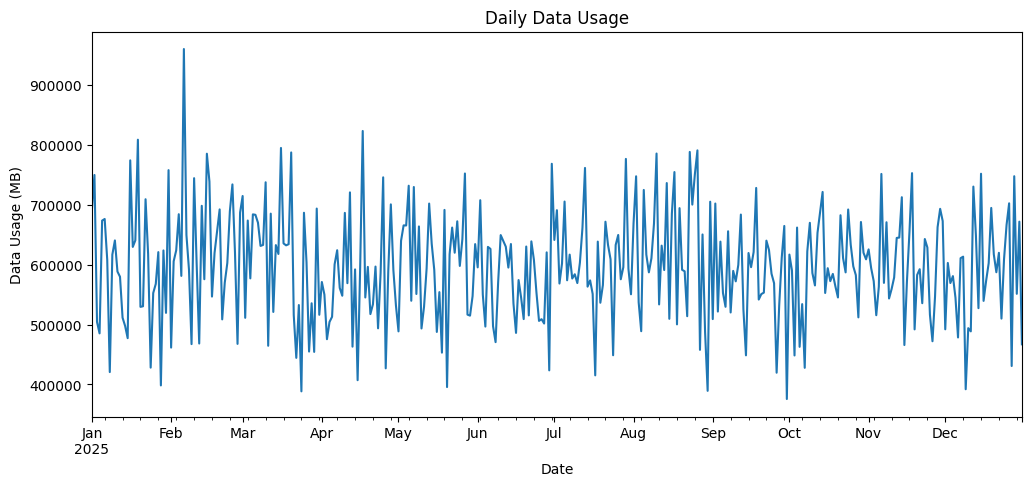

In [54]:
plt.figure(figsize=(12,5))

daily_usage.plot()

plt.title("Daily Data Usage")
plt.xlabel("Date")
plt.ylabel("Data Usage (MB)")

plt.show()

In [55]:
df.groupby("is_weekend")["voice_minutes"].mean()

,voice_minutes
is_weekend,
False,133.609727
True,132.923401


In [56]:
df.groupby("is_weekend")["data_usage_mb"].mean()

,data_usage_mb
is_weekend,
False,3966.72464
True,3955.15256


In [57]:
df.groupby("peak_hour")["data_usage_mb"].mean()

,data_usage_mb
peak_hour,
False,2407.422414
True,5792.988290


In [58]:
from scipy.stats import ttest_ind

In [59]:
urban = df.loc[
    df["urban_rural"] == "Urban",
    "avg_download_mbps"
]

rural = df.loc[
    df["urban_rural"] == "Rural",
    "avg_download_mbps"
]

t_stat, p_value = ttest_ind(
    urban,
    rural,
    equal_var=False
)

print("t-statistic:", t_stat)
print("p-value:", p_value)

t-statistic: 95.35636032629668
p-value: 0.0


In [60]:
urban_mean = urban.mean()
rural_mean = rural.mean()

difference = urban_mean - rural_mean

print("Urban mean:", urban_mean)
print("Rural mean:", rural_mean)
print("Difference:", difference)

Urban mean: 47.04681784874079
Rural mean: 13.88373828729732
Difference: 33.16307956144347


An independent Welch's t-test was conducted to compare average download speeds between Urban and Rural areas. The test produced a t-statistic of 95.36 and an extremely small p-value (p < 0.001), indicating a statistically significant difference in average download speeds between the two area types. Since the t-statistic is positive, and assuming Urban observations have the higher mean, the results indicate that Urban areas have significantly higher average download speeds than Rural areas.

In [61]:
df["active_user_rate"] = (
    df["active_users"] / df["subscriber_count"]
) * 100

In [62]:
df["churn_rate"] = (
    df["churned_subscribers"] / df["subscriber_count"]
) * 100

In [63]:
df["avg_call_duration"] = (
    df["voice_minutes"] / df["voice_calls"]
)

In [64]:
df["revenue_per_active_user"] = (
    df["revenue_ghs"] / df["active_users"]
)

In [65]:
df["total_sms"] = (
    df["sms_sent"] + df["sms_received"]
)

In [66]:
df["data_per_session"] = (
    df["data_usage_mb"] / df["data_sessions"]
)

In [67]:
df["complaints_per_1000"] = (
    df["customer_complaints"] / df["subscriber_count"]
) * 1000

In [68]:
(df["subscriber_count"] == 0).sum()
(df["voice_calls"] == 0).sum()
(df["data_sessions"] == 0).sum()
df["avg_call_duration"] = np.where(
    df["voice_calls"] > 0,
    df["voice_minutes"] / df["voice_calls"],
    0
)

In [69]:
new_features = [
    "active_user_rate",
    "churn_rate",
    "revenue_per_active_user",
    "avg_call_duration",
    "total_sms",
    "data_per_session",
    "complaints_per_1000"
]

df[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
active_user_rate,55000.0,66.922511,13.014206,43.396226,55.932203,66.909120,78.000000,89.937107
churn_rate,55000.0,1.206521,1.490502,0.000000,0.000000,0.710900,2.000000,16.000000
revenue_per_active_user,55000.0,0.328965,0.253418,0.013667,0.151696,0.255017,0.429503,2.912083
avg_call_duration,55000.0,5.436436,3.730466,0.000000,2.712057,4.636364,7.285714,42.888889
total_sms,55000.0,102.303782,128.953679,1.000000,29.000000,55.000000,118.000000,1260.000000
data_per_session,55000.0,44.729081,28.182423,0.581395,23.954371,39.069902,59.306515,257.931034
complaints_per_1000,55000.0,20.589690,22.617831,0.000000,3.773585,14.084507,30.927835,260.000000


1. Active User Rate
Statistic	Value
Mean	66.92%
Std	13.01%
Median	66.91%
Q1	55.93%
Q3	78.00%
Min	43.40%
Max	89.94%


Statistical interpretation
The average active user rate is approximately 66.9%.
The median is also 66.9%:
Mean ≈ Median

This is important because it suggests the distribution is fairly symmetric, with relatively little influence from extreme values.
The standard deviation is 13.01 percentage points, meaning there is moderate variation in active-user rates across observations.
The middle 50% of observations lie between:
55.93% and 78.00%
So most observations are reasonably concentrated around the mid-to-high 60% range.
Insight
Active user rates are relatively stable compared with some of the other variables. The similarity between the mean and median suggests limited skewness, while the standard deviation of 13 percentage points indicates moderate variation across observations.

2. Churn Rate
Statistic	Value
Mean	1.21%
Std	1.49%
Median	0%
Q1	0%
Q3	0.71%
Min	0%
Max	16%


This one is very interesting statistically.
Your mean is:
1.21%
but your median is:
0%
And your Q1 is also:
0%
That means at least 25% of observations have a churn rate of 0%, and because the median is also 0%, at least 50% of observations have churn rates at or below 0%, which here means exactly 0%.
Yet your maximum is 16%.
What does this tell us?
The distribution is strongly positively/right skewed.
Most observations have very low or zero churn, while a smaller number have substantially higher churn rates.
This explains why:
Mean = 1.21%
Median = 0%

The higher churn observations are pulling the mean upward.
Insight
Churn is highly concentrated at zero or very low levels, with a relatively small number of observations experiencing substantially higher churn. The mean of 1.21% therefore does not fully represent the typical observation, as indicated by the median of 0%.

This is a very good example of why you shouldn't rely on the mean alone.

3. Revenue per Active User
Statistic	Value
Mean	0.329
Std	0.253
Median	0.255
Q1	0.152
Q3	0.430
Min	0.014
Max	2.912


The mean is:
0.329
while the median is:
0.255
The mean is noticeably higher than the median.
That suggests positive/right skewness.
The maximum of 2.912 is also considerably higher than the 75th percentile of 0.430.
So there are some observations with exceptionally high revenue per active user.
Insight
Revenue per active user shows substantial variation and positive skewness. The mean of 0.329 exceeds the median of 0.255, indicating that higher-value observations are pulling the average upward. The maximum of 2.912 also suggests the presence of potentially influential high-revenue observations.

You should investigate those high values rather than automatically calling them errors.

4. Average Call Duration
Statistic	Value
Mean	5.44
Std	3.73
Median	4.64
Q1	2.71
Q3	7.29
Min	0
Max	42.89


Again:
Mean = 5.44
Median = 4.64
The mean is higher than the median, suggesting right skewness.
Most observations fall between approximately:
2.71 and 7.29
But the maximum is:
42.89
That's dramatically higher than the typical observation.
Insight
Average call duration is positively skewed, with most observations concentrated between approximately 2.7 and 7.3 units, while a small number of observations have substantially longer call durations.

Those high values could represent heavy users, particular locations, unusual usage patterns, or data anomalies.

5. Total SMS
Statistic	Value
Mean	102.30
Std	128.95
Median	55
Q1	29
Q3	118
Min	1
Max	1,260


This is strongly right-skewed.
Look at:
Mean = 102
versus:
Median = 55
The mean is almost twice the median.
And:
Std = 129
which is larger than the mean.
The maximum is:
1,260 SMS
while 75% of observations have 118 or fewer.
Statistical interpretation
SMS usage is highly dispersed and positively skewed. The large difference between the mean and median indicates that a relatively small number of high-SMS users substantially increase the average.

This is an excellent example where the median may be more representative of the typical customer than the mean.

6. Data per Session
Statistic	Value
Mean	44.73
Std	28.18
Median	39.07
Q1	23.95
Q3	59.31
Min	0.58
Max	257.93


Here:
Mean = 44.73
Median = 39.07
Again, the mean is higher than the median, suggesting moderate positive skewness.
The middle 50% of observations are between:
23.95 and 59.31
But the maximum reaches:
257.93
which is much higher than the typical range.
Insight
Data usage per session shows moderate variability and positive skewness. Most observations fall between approximately 24 and 59 units, while a small number of high-usage observations extend the distribution considerably upward.

7. Complaints per 1,000
Statistic	Value
Mean	20.59
Std	22.62
Median	14.08
Q1	3.77
Q3	30.93
Min	0
Max	260


This is another variable with strong positive skewness.
Mean:
20.59
Median:
14.08
Maximum:
260
while 75% of observations have complaints below approximately 30.93 per 1,000.
The maximum of 260 is extremely high relative to the typical range.
Insight
Complaints per 1,000 show substantial variability and positive skewness. Most observations have relatively low complaint rates, but a smaller number of observations experience substantially higher complaint levels. These high-complaint observations warrant further investigation.

Now look at all seven variables together
This is where EDA becomes really useful.
Variable	Mean vs Median	Variability	Distribution
Active user rate	Almost identical	Moderate	Relatively symmetric
Churn rate	1.21% vs 0%	High relative to mean	Strongly right-skewed
Revenue per active user	0.329 vs 0.255	High	Right-skewed
Avg call duration	5.44 vs 4.64	Moderate/high	Right-skewed
Total SMS	102 vs 55	Very high	Strongly right-skewed
Data per session	44.73 vs 39.07	Moderate	Right-skewed
Complaints per 1,000	20.59 vs 14.08	High	Right-skewed

In [70]:
df[new_features].isnull().sum()

,0
active_user_rate,0
churn_rate,0
revenue_per_active_user,0
avg_call_duration,0
total_sms,0
data_per_session,0
complaints_per_1000,0


In [71]:
df[new_features].replace([np.inf, -np.inf], np.nan).isnull().sum()

,0
active_user_rate,0
churn_rate,0
revenue_per_active_user,0
avg_call_duration,0
total_sms,0
data_per_session,0
complaints_per_1000,0


In [72]:
encoded = pd.get_dummies(
    df,
    columns=["technology"],
    drop_first=True
)

In [73]:
from sklearn.preprocessing import StandardScaler

In [74]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df[[
        "subscriber_count",
        "active_users",
        "data_usage_mb",
        "revenue_ghs"
    ]]
)

K-MEANS CLUSTERING
This is where things get interesting.
K-Means answers:
Can we automatically discover groups of similar observations?

and discover groups such as:
Cluster 0
High usage + high revenue + high satisfaction
Cluster 1
Low usage + low revenue + moderate satisfaction
Cluster 2
High usage + low satisfaction + many complaints
The algorithm doesn't know those business names.
We interpret the clusters afterward.

In [75]:
cluster_features = [
    "data_usage_mb",
    "voice_minutes",
    "revenue_ghs",
    "customer_satisfaction",
    "customer_complaints"
]

In [76]:
df[cluster_features].isnull().sum()

,0
data_usage_mb,0
voice_minutes,0
revenue_ghs,0
customer_satisfaction,0
customer_complaints,0


In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(
    df[cluster_features]
)

In [78]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

In [79]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

In [80]:
df["cluster"] = clusters

In [81]:
df["cluster"].value_counts().sort_index()

,count
cluster,
0,29741
1,3670
2,21589


This only tells you how many observations are in each cluster.

In [82]:
cluster_profile = df.groupby("cluster")[
    cluster_features
].mean()

cluster_profile

,data_usage_mb,voice_minutes,revenue_ghs,customer_satisfaction,customer_complaints
cluster,,,,,
0,2603.930971,93.039003,24.098933,8.285296,0.998521
1,21894.107902,653.988283,198.907891,7.966678,1.972752
2,2788.164343,100.540692,25.794966,7.553990,2.840474


This is where YOU interpret the model.
For example, if Cluster 1 has:
- high data usage
- high revenue
- high satisfaction
you might call it:
High-value satisfied users

If Cluster 2 has:
- high usage
- low satisfaction
- high complaints
you might call it:
High-value dissatisfied users


Cluster 0 — Low-use, satisfied customers
These customers have:
- ~2.6 GB data usage
- ~93 voice minutes
- ~GHS 24 revenue
- highest satisfaction: 8.29
- lowest complaints: ~1
I'd describe this group as:
Low-value but satisfied customers

They aren't generating much revenue, but their experience appears relatively good.
Cluster 1 — High-value / high-usage customers
This is the most interesting cluster.
Compared with the other groups, these customers have dramatically higher:
- Data usage → 21.9 GB
- Voice usage → 654 minutes
- Revenue → GHS 198.91
That's roughly 8× the revenue of the other clusters.
Yet their satisfaction is only:
7.97

And complaints are:
1.97

So these are:
High-value, high-usage customers with moderate customer-experience issues.

From a telecom business perspective, this is potentially your most commercially important cluster.
Why?
Because losing these customers could have a much bigger revenue impact than losing a low-value customer.
Cluster 2 — Low-use, dissatisfied customers
This group has:
- ~2.8 GB data
- ~101 voice minutes
- ~GHS 25.79 revenue
- lowest satisfaction: 7.55
- highest complaints: 2.84
This is the most obvious customer-experience problem group.
I'd label it:
Low-value, dissatisfied customers

They aren't generating much revenue, but they are experiencing more complaints and lower satisfaction.
Now notice something important

Customer complaints might be a strong indicator of churn risk.

Your clustering result provides some supporting evidence.
Look at:
Cluster 0
Complaints = 1.00
Satisfaction = 8.29

Cluster 1
Complaints = 1.97
Satisfaction = 7.97

Cluster 2
Complaints = 2.84
Satisfaction = 7.55

There's a very clear pattern:
Complaints ↑ → Satisfaction ↓
But we still haven't proven that complaints predict churn.
That's something we'll test later with classification.

In [83]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [84]:
inertia = []
silhouette_scores = []

K_range = range(2, 8)

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertia.append(model.inertia_)

    silhouette_scores.append(
        silhouette_score(X, labels)
    )

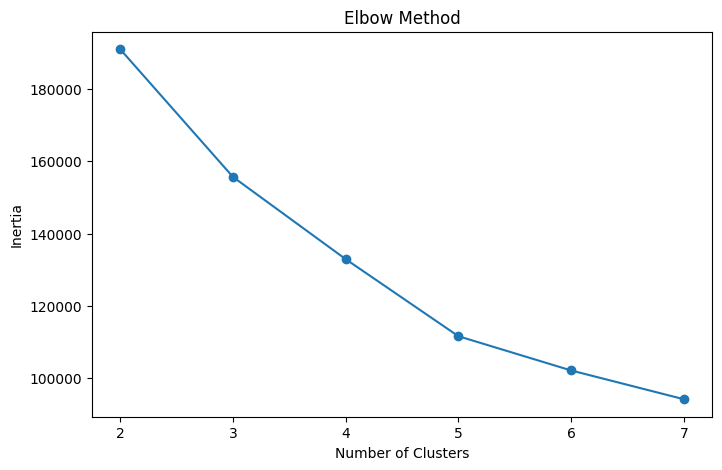

In [85]:
plt.figure(figsize=(8,5))

plt.plot(K_range, inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

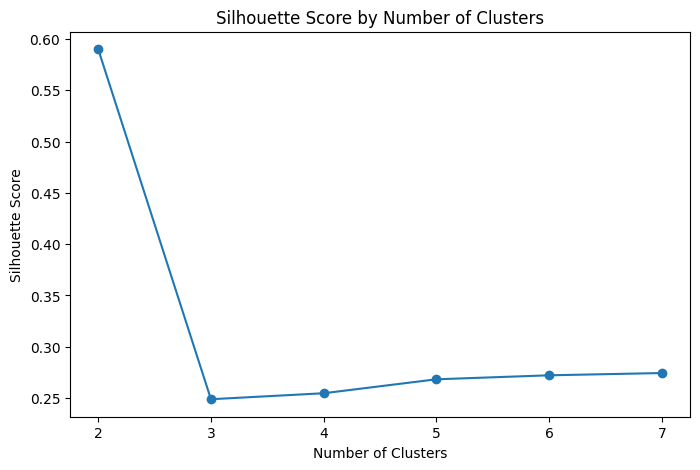

In [86]:
plt.figure(figsize=(8,5))

plt.plot(K_range, silhouette_scores, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")

plt.show()

Perfect. Your results are:
- Elbow: K = 3
- Highest silhouette score: K = 2
- They do not agree
What does that mean?
This is actually a good data-mining situation. There is no automatic rule that says one method must win.
- Elbow = 3 → moving from 2 to 3 clusters gives a meaningful reduction in within-cluster variation.
- Silhouette = 2 → the observations are most cleanly separated into 2 groups.
Since the two methods disagree, we compare the business usefulness and cluster quality rather than blindly choosing one.

In [87]:
for k in [2, 3]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    print(f"\n===== K = {k} =====")
    print("Inertia:", model.inertia_)
    print("Silhouette:", silhouette_score(X, labels))


===== K = 2 =====
Inertia: 191061.89683685082
Silhouette: 0.5899575899912568

===== K = 3 =====
Inertia: 155699.84868993636
Silhouette: 0.24888517692589046


In [88]:
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)

df["cluster_2"] = kmeans_2.fit_predict(X)

cluster_profile_2 = df.groupby("cluster_2")[cluster_features].mean()

cluster_profile_2

,data_usage_mb,voice_minutes,revenue_ghs,customer_satisfaction,customer_complaints
cluster_2,,,,,
0,2593.841010,93.019675,23.999633,7.978162,1.766915
1,20644.958064,625.418644,187.820872,7.962557,2.025641


In [89]:
cluster_profile_3 = df.groupby("cluster")[cluster_features].mean()

cluster_profile_3

,data_usage_mb,voice_minutes,revenue_ghs,customer_satisfaction,customer_complaints
cluster,,,,,
0,2603.930971,93.039003,24.098933,8.285296,0.998521
1,21894.107902,653.988283,198.907891,7.966678,1.972752
2,2788.164343,100.540692,25.794966,7.553990,2.840474


In [90]:
pca_features = [
    "data_usage_mb",
    "voice_minutes",
    "revenue_ghs",
    "customer_satisfaction",
    "customer_complaints",
    "avg_download_mbps",
    "avg_upload_mbps",
    "latency_ms",
    "packet_loss_pct"
]

In [91]:
df[pca_features].isnull().sum()

,0
data_usage_mb,0
voice_minutes,0
revenue_ghs,0
customer_satisfaction,0
customer_complaints,0
avg_download_mbps,0
avg_upload_mbps,0
latency_ms,0
packet_loss_pct,0


In [92]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_pca = scaler.fit_transform(df[pca_features])

In [93]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca_transformed = pca.fit_transform(X_pca)

In [94]:
pca.explained_variance_ratio_

array([0.28762829, 0.26389268, 0.14407349, 0.1041908 , 0.08277369,
       0.05603806, 0.04893576, 0.01080302, 0.00166421])

That would mean:
- Component 1 explains 31%
- Component 2 explains 21%
- Component 3 explains 14%
etc.

In [95]:
import numpy as np

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

cumulative_variance

array([0.28762829, 0.55152097, 0.69559446, 0.79978526, 0.88255895,
       0.93859701, 0.98753277, 0.99833579, 1.        ])

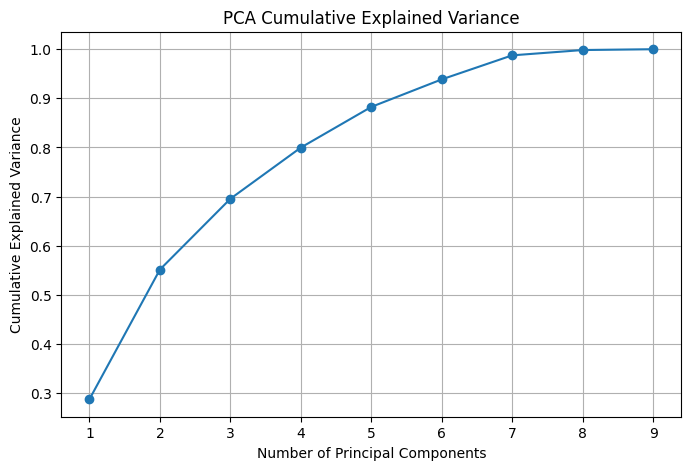

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True)

plt.show()

A common approach is to retain around 80–95% of the variance, depending on the objective.
For example:
Components	Variance retained
1	31%
2	52%
3	66%
4	76%
5	84%
6	90%


If you wanted at least 80%, you could use 5 components.
Notice what happened:
9 original variables → 5 components

That's dimensionality reduction.

In [97]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(pca.components_))],
    index=pca_features
)

loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
data_usage_mb,0.557873,-0.168240,-0.159990,0.049682,0.043028,-0.406325,0.003000,-0.002275,-0.682233
voice_minutes,0.465628,-0.142878,-0.101613,0.009282,0.011345,0.863808,-0.026224,-0.000150,-0.073375
revenue_ghs,0.570124,-0.171988,-0.160280,0.047615,0.043416,-0.293887,0.000842,0.001831,0.727436
customer_satisfaction,0.112105,0.511248,-0.182331,-0.000229,0.055634,0.026980,0.825597,-0.085903,-0.000306
customer_complaints,0.051809,-0.094720,0.448191,0.831383,-0.261126,0.008715,0.166988,-0.011109,0.000274
avg_download_mbps,0.223068,0.557025,0.203197,-0.009344,-0.031299,-0.011385,-0.251834,0.730790,-0.002027
avg_upload_mbps,0.220127,0.544316,0.213655,-0.008813,-0.034540,-0.014641,-0.387387,-0.676800,0.002121
latency_ms,0.158941,-0.161212,0.482243,-0.528257,-0.620194,-0.034863,0.225899,-0.015736,0.000858
packet_loss_pct,0.090539,-0.137144,0.620300,-0.157354,0.733512,-0.001727,0.159021,-0.011404,-0.001042


The loadings tell us which original variables contribute most to each component.
For example, if PC1 has high positive loadings for:
- data usage
- voice minutes
- revenue
we might interpret PC1 as something like:
Overall customer usage/value

If PC2 has strong loadings for:
- satisfaction
- complaints
we might interpret it as:
Customer experience

These aren't official names produced by PCA. We interpret the components based on their loadings.

In [98]:
pca.explained_variance_ratio_

array([0.28762829, 0.26389268, 0.14407349, 0.1041908 , 0.08277369,
       0.05603806, 0.04893576, 0.01080302, 0.00166421])

In [99]:
cumulative_variance

array([0.28762829, 0.55152097, 0.69559446, 0.79978526, 0.88255895,
       0.93859701, 0.98753277, 0.99833579, 1.        ])

In [100]:
loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
data_usage_mb,0.557873,-0.168240,-0.159990,0.049682,0.043028,-0.406325,0.003000,-0.002275,-0.682233
voice_minutes,0.465628,-0.142878,-0.101613,0.009282,0.011345,0.863808,-0.026224,-0.000150,-0.073375
revenue_ghs,0.570124,-0.171988,-0.160280,0.047615,0.043416,-0.293887,0.000842,0.001831,0.727436
customer_satisfaction,0.112105,0.511248,-0.182331,-0.000229,0.055634,0.026980,0.825597,-0.085903,-0.000306
customer_complaints,0.051809,-0.094720,0.448191,0.831383,-0.261126,0.008715,0.166988,-0.011109,0.000274
avg_download_mbps,0.223068,0.557025,0.203197,-0.009344,-0.031299,-0.011385,-0.251834,0.730790,-0.002027
avg_upload_mbps,0.220127,0.544316,0.213655,-0.008813,-0.034540,-0.014641,-0.387387,-0.676800,0.002121
latency_ms,0.158941,-0.161212,0.482243,-0.528257,-0.620194,-0.034863,0.225899,-0.015736,0.000858
packet_loss_pct,0.090539,-0.137144,0.620300,-0.157354,0.733512,-0.001727,0.159021,-0.011404,-0.001042


The three concepts you must understand
There are three major measures.
Support
How frequently does the combination occur?
\[
Support(A \rightarrow B) =
\frac{\text{transactions containing A and B}}
{\text{total transactions}}
\]
Example:
If 20% of records contain both:
5G + High Data Usage

then support = 20%.
Confidence
When A occurs, how often does B occur?
\[
Confidence(A \rightarrow B)
=
\frac{Support(A,B)}{Support(A)}
\]
Example:
Suppose:
- 40% of records have 5G
- 30% have both 5G and high data usage
Then:
\[
Confidence = \frac{30\%}{40\%}=75\%
\]
Meaning:
Among records with 5G, 75% also have high data usage.

Lift
This is the really important one.
Lift asks:
Is the relationship stronger than what we'd expect by chance?

\[
Lift(A \rightarrow B)
=
\frac{Confidence(A \rightarrow B)}
{Support(B)}
\]
Interpretation:
- Lift > 1 → positive association
- Lift = 1 → approximately independent
- Lift < 1 → negative association
For example:
Lift = 2.5

means the combination occurs about 2.5 times more often than expected if the two events were independent.

In [101]:
data_threshold = df["data_usage_mb"].median()

df["high_data_usage"] = (
    df["data_usage_mb"] > data_threshold
).astype(int)

In [102]:
df["high_congestion"] = (
    df["congestion_level"] == "High"
).astype(int)

In [103]:
df["peak"] = (
    df["peak_hour"] == True
).astype(int)

In [104]:
df["urban"] = (
    df["urban_rural"] == "Urban"
).astype(int)

In [105]:
df["poor_network"] = (
    df["network_performance_score"] == "Low"
).astype(int)

In [106]:
basket = df[
    [
        "high_data_usage",
        "high_congestion",
        "peak",
        "urban",
        "poor_network"
    ]
].astype(bool)

In [107]:
!pip install mlxtend

In [108]:
from mlxtend.frequent_patterns import apriori

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [109]:
frequent_itemsets = apriori(
    basket,
    min_support=0.10,
    use_colnames=True
)

frequent_itemsets.sort_values(
    "support",
    ascending=False
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets
0,0.499927,(high_data_usage)
2,0.471436,(urban)
1,0.459600,(peak)
3,0.306418,"(peak, high_data_usage)"
4,0.275291,"(urban, high_data_usage)"
5,0.215545,"(peak, urban)"
6,0.158582,"(peak, urban, high_data_usage)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [110]:
from mlxtend.frequent_patterns import association_rules

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [111]:
rules = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=1.0
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [112]:
rules.sort_values(
    "lift",
    ascending=False
)[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
9,(high_data_usage),"(peak, urban)",0.158582,0.317210,1.471661
4,"(peak, urban)",(high_data_usage),0.158582,0.735723,1.471661
1,(high_data_usage),(peak),0.306418,0.612926,1.333606
0,(peak),(high_data_usage),0.306418,0.666706,1.333606
6,"(urban, high_data_usage)",(peak),0.158582,0.576052,1.253376
7,(peak),"(urban, high_data_usage)",0.158582,0.345043,1.253376
2,(urban),(high_data_usage),0.275291,0.583941,1.168051
3,(high_data_usage),(urban),0.275291,0.550662,1.168051
5,"(peak, high_data_usage)",(urban),0.158582,0.517534,1.097781
8,(urban),"(peak, high_data_usage)",0.158582,0.336380,1.097781


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


antecedents: {high_congestion}
consequents: {poor_network}

support: 0.18
confidence: 0.65
lift: 1.40

You could say:
18% of observations contain both high congestion and poor network performance. Among observations with high congestion, 65% also have poor network performance. The lift of 1.40 indicates that poor network performance occurs 40% more often with high congestion than would be expected under independence.

| Technique | Question |
|---|---|
| EDA | What's happening? |
| Correlation | Which variables move together? |
| T-test | Are two groups statistically different? |
| K-Means | What natural groups exist? |
| PCA | Can I reduce many variables into fewer dimensions? |
| Association Rules | What events/items occur together? |

In [113]:
churn_risk

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

array(['Medium', 'Low', 'Low', ..., 'Medium', 'Low', 'Low'], dtype='<U6')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [114]:
df["churn_risk"].value_counts()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
churn_risk,
Low,45388
Medium,8794
High,818


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [115]:
df["churn_risk"].value_counts(normalize=True) * 100

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,proportion
churn_risk,
Low,82.523636
Medium,15.989091
High,1.487273


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [116]:
features = [
    "subscriber_count",
    "active_users",
    "new_subscribers",
    "voice_calls",
    "voice_minutes",
    "sms_sent",
    "sms_received",
    "data_sessions",
    "data_usage_mb",
    "avg_download_mbps",
    "avg_upload_mbps",
    "latency_ms",
    "packet_loss_pct",
    "signal_strength_dbm",
    "signal_quality_db",
    "dropped_calls",
    "call_setup_success_rate",
    "handover_success_rate",
    "network_availability_pct",
    "tower_utilization_pct",
    "revenue_ghs",
    "customer_complaints",
    "customer_satisfaction",
    "outage_minutes"
]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [117]:
X = df[features]
y = df["churn_risk"]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [118]:
X.shape

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

(55000, 24)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [119]:
y.value_counts()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
churn_risk,
Low,45388
Medium,8794
High,818


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [120]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [121]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [122]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

LogisticRegression(max_iter=1000, random_state=42)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [123]:
y_pred = model.predict(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [124]:
y_prob = model.predict_proba(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [125]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Accuracy: 0.9980909090909091


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [126]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Accuracy: 0.9980909090909091


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

A terrible model that predicts Low every time could already achieve around 80% accuracy.
That's why classification requires more detailed evaluation.

In [127]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

[[ 161    0    3]
 [   0 9073    4]
 [   3   11 1745]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

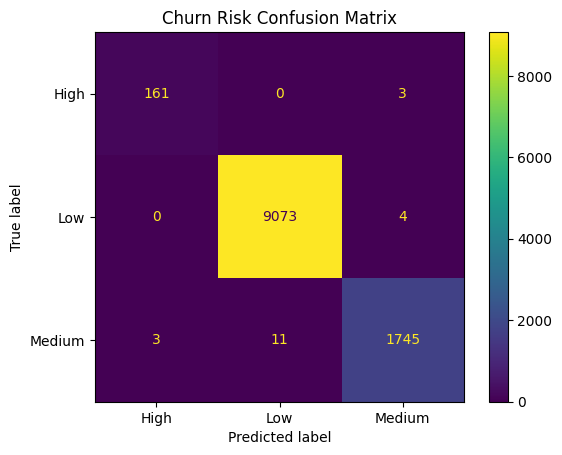

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [128]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
).plot()

plt.title("Churn Risk Confusion Matrix")
plt.show()

In [129]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

              precision    recall  f1-score   support

        High       0.98      0.98      0.98       164
         Low       1.00      1.00      1.00      9077
      Medium       1.00      0.99      0.99      1759

    accuracy                           1.00     11000
   macro avg       0.99      0.99      0.99     11000
weighted avg       1.00      1.00      1.00     11000



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [130]:
df["churn_risk"].value_counts()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
churn_risk,
Low,45388
Medium,8794
High,818


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [131]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Accuracy: 0.9980909090909091


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

              precision    recall  f1-score   support

        High       0.98      0.98      0.98       164
         Low       1.00      1.00      1.00      9077
      Medium       1.00      0.99      0.99      1759

    accuracy                           1.00     11000
   macro avg       0.99      0.99      0.99     11000
weighted avg       1.00      1.00      1.00     11000



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [132]:
df.groupby("churn_risk")[[
    "customer_complaints",
    "customer_satisfaction",
    "outage_minutes",
    "avg_download_mbps",
    "latency_ms",
    "packet_loss_pct",
    "revenue_ghs"
]].mean()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,customer_complaints,customer_satisfaction,outage_minutes,avg_download_mbps,latency_ms,packet_loss_pct,revenue_ghs
churn_risk,,,,,,,
High,5.182152,6.897958,82.246944,28.726822,59.601577,3.322676,44.432726
Low,1.496166,8.096540,0.055676,35.850525,53.230763,2.063174,34.228726
Medium,2.969411,7.460256,1.101774,24.472035,63.011094,3.429097,47.041900


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [133]:
df.groupby("churn_risk")[features].mean().T

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

churn_risk,High,Low,Medium
subscriber_count,168.119804,164.849277,166.660450
active_users,115.037897,109.288248,118.521606
new_subscribers,1.909535,1.856658,1.865363
voice_calls,29.002445,23.126487,31.732772
voice_minutes,152.673594,125.608972,171.907664
sms_sent,55.520782,44.977880,61.402888
sms_received,63.768949,51.375936,70.030134
data_sessions,103.764059,83.572310,114.269275
data_usage_mb,4864.896088,3724.551049,5112.481123
avg_download_mbps,28.726822,35.850525,24.472035


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [134]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

tree.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

DecisionTreeClassifier(max_depth=5, random_state=42)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [135]:
tree_pred = tree.predict(X_test)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [136]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, tree_pred))

print(
    classification_report(
        y_test,
        tree_pred
    )
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Accuracy: 0.9227272727272727


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

              precision    recall  f1-score   support

        High       0.84      0.63      0.72       164
         Low       0.96      0.96      0.96      9077
      Medium       0.75      0.78      0.76      1759

    accuracy                           0.92     11000
   macro avg       0.85      0.79      0.81     11000
weighted avg       0.92      0.92      0.92     11000



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [137]:
train_accuracy = tree.score(X_train, y_train)
test_accuracy = tree.score(X_test, y_test)

print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Training accuracy: 0.9285909090909091
Testing accuracy: 0.9227272727272727


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

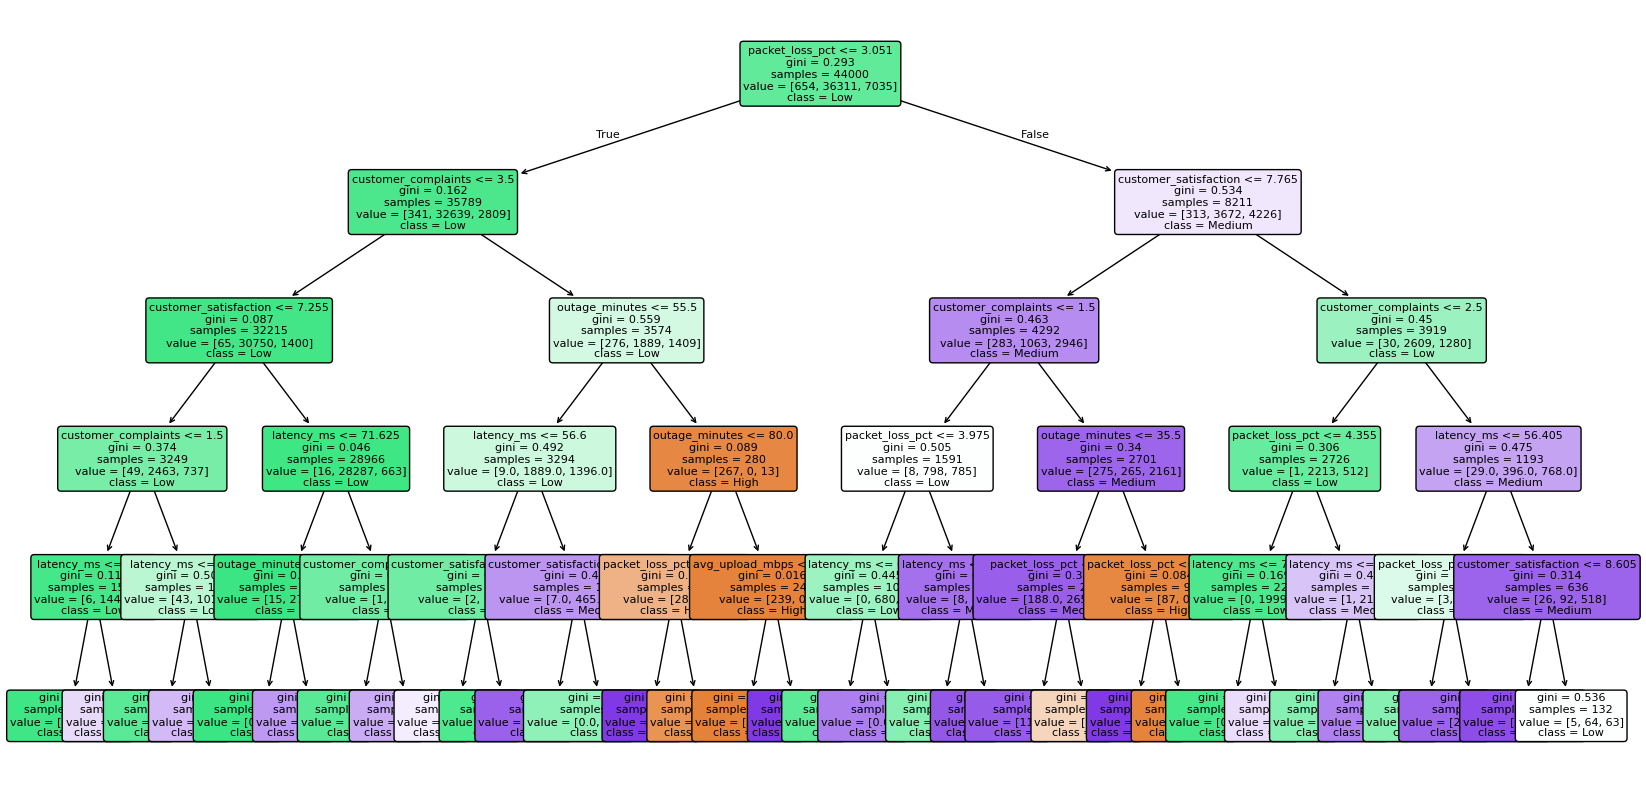

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [138]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    tree,
    feature_names=features,
    class_names=tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

In [139]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": tree.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,feature,importance
12,packet_loss_pct,0.401730
21,customer_complaints,0.236436
22,customer_satisfaction,0.153591
11,latency_ms,0.137303
23,outage_minutes,0.070693
10,avg_upload_mbps,0.000246
0,subscriber_count,0.000000
1,active_users,0.000000
7,data_sessions,0.000000
6,sms_received,0.000000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Excellent. This is a much healthier result than the ~100% logistic regression result.
Your Decision Tree
Metric	Result
Training accuracy	92.86%
Testing accuracy	92.27%
Difference	0.59 percentage points


Interpretation
The important thing here is the small gap between training and testing accuracy.
Your model:
- learns the training data reasonably well → 92.86%
- performs similarly on unseen data → 92.27%
- has only about a 0.6% generalization gap
That suggests little evidence of overfitting at max_depth=5.
This is exactly the kind of comparison you should make when evaluating a model.
A model isn't good simply because training accuracy is high. We want good performance on unseen data.

One thing I want you to notice
Your tree's 92.27% test accuracy is lower than the logistic regression's ~100%.
That does not automatically mean logistic regression is better.
Remember our suspicion:
The logistic model may be exploiting leakage or very strong synthetic relationships.

So we're going to compare the models more carefully.

In [140]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_results = []

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [141]:
model_results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "High_Precision": precision_score(
        y_test, y_pred, labels=["High"], average="macro"
    ),
    "High_Recall": recall_score(
        y_test, y_pred, labels=["High"], average="macro"
    ),
    "High_F1": f1_score(
        y_test, y_pred, labels=["High"], average="macro"
    )
})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [142]:
model_results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, tree_pred),
    "High_Precision": precision_score(
        y_test, tree_pred, labels=["High"], average="macro"
    ),
    "High_Recall": recall_score(
        y_test, tree_pred, labels=["High"], average="macro"
    ),
    "High_F1": f1_score(
        y_test, tree_pred, labels=["High"], average="macro"
    )
})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [143]:
model_results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "High_Precision": precision_score(
        y_test, rf_pred, labels=["High"], average="macro"
    ),
    "High_Recall": recall_score(
        y_test, rf_pred, labels=["High"], average="macro"
    ),
    "High_F1": f1_score(
        y_test, rf_pred, labels=["High"], average="macro"
    )
})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

NameError: name 'rf_pred' is not defined

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
comparison = pd.DataFrame(model_results)

comparison

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

for name, predictions in [
    ("Logistic Regression", y_pred),
    ("Decision Tree", tree_pred),
    ("Random Forest", rf_pred)
]:

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=["High"]
    )

    print(name)
    print("Precision:", precision[0])
    print("Recall:", recall[0])
    print("F1:", f1[0])
    print("Support:", support[0])
    print()

In [ ]:
from sklearn.metrics import roc_auc_score

rf_prob = rf.predict_proba(X_test)

auc = roc_auc_score(
    y_test,
    rf_prob,
    multi_class="ovr"
)

print("Random Forest ROC-AUC:", auc)

In [144]:
Q1 = df["latency_ms"].quantile(0.25)
Q3 = df["latency_ms"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Lower bound: 25.405
Upper bound: 84.405


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [146]:
df["latency_anomaly"] = (
    (df["latency_ms"] < lower_bound) |
    (df["latency_ms"] > upper_bound)
)

df["latency_anomaly"].value_counts()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
latency_anomaly,
False,54711
True,289


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [147]:
df["high_latency_anomaly"] = (
    df["latency_ms"] > upper_bound
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [148]:
site_stats = df.groupby("site_id")["latency_ms"].agg(
    ["mean", "std", "count"]
)

site_stats.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,mean,std,count
site_id,,,
SITE-01000,57.520000,12.159579,5
SITE-01001,55.826154,10.941126,13
SITE-01002,56.065714,10.120041,7
SITE-01003,50.330000,9.525175,6
SITE-01004,54.980000,10.871224,8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [149]:
df_anomaly = df.join(
    site_stats,
    on="site_id",
    rsuffix="_site"
)

df_anomaly["site_z_score"] = (
    (df_anomaly["latency_ms"] - df_anomaly["mean"]) /
    df_anomaly["std"]
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [150]:
df_anomaly["site_latency_anomaly"] = (
    df_anomaly["site_z_score"] > 2
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [151]:
spatial_summary = (
    df.groupby(["region", "district"])
    .agg(
        records=("record_id", "count"),
        avg_latency=("latency_ms", "mean"),
        avg_download=("avg_download_mbps", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_availability=("network_availability_pct", "mean"),
        total_complaints=("customer_complaints", "sum"),
        population_density=("population_density", "mean")
    )
    .reset_index()
)

spatial_summary.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,region,district,records,avg_latency,avg_download,avg_packet_loss,avg_availability,total_complaints,population_density
0,Ahafo,Asunafo South,390,53.889769,33.748846,2.279108,98.984897,679,246.200051
1,Ahafo,Goaso Municipal,434,54.464147,28.208364,2.329459,98.992074,777,248.164101
2,Ahafo,Kenyasi,380,54.848974,33.163447,2.260487,98.987211,734,245.499579
3,Ahafo,Tano North,394,54.266701,27.450584,2.249624,98.945152,713,250.807538
4,Ashanti,Asokwa Municipal,1626,54.673506,40.421839,2.315336,98.997109,2982,1483.585750


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [152]:
# Exclude districts with too few observations
eligible_districts = spatial_summary[
    spatial_summary["records"] >= 30
]

latency_hotspots = eligible_districts.sort_values(
    "avg_latency",
    ascending=False
)

latency_hotspots.head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,region,district,records,avg_latency,avg_download,avg_packet_loss,avg_availability,total_complaints,population_density
42,Oti,Jasikan,380,55.857105,33.957526,2.220363,99.023395,714,178.109789
22,Eastern,Akuapem North,884,55.555407,29.208179,2.364697,99.023462,1579,707.490713
43,Oti,Nkwanta South,351,55.478234,29.445385,2.341151,99.006296,633,181.044302
28,Greater Accra,Ga East,1497,55.451764,43.164369,2.331530,98.990401,2812,2504.575845
37,Northern,Sagnarigu Municipal,762,55.447257,30.442100,2.324770,98.978648,1407,353.877152
66,Western North,Sefwi Wiawso,834,55.430300,32.404460,2.346855,98.996942,1504,249.224664
33,North East,Garu,552,55.384275,29.655851,2.355502,98.959022,978,150.161612
19,Central,Cape Coast Metropolitan,814,55.370160,29.308206,2.355280,99.000528,1388,743.513342
7,Ashanti,Kwadaso Municipal,1560,55.366788,42.993526,2.276093,98.986583,2830,1494.711763
29,Greater Accra,Ga South,1437,55.366270,40.866152,2.336168,98.996451,2608,2489.777766


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

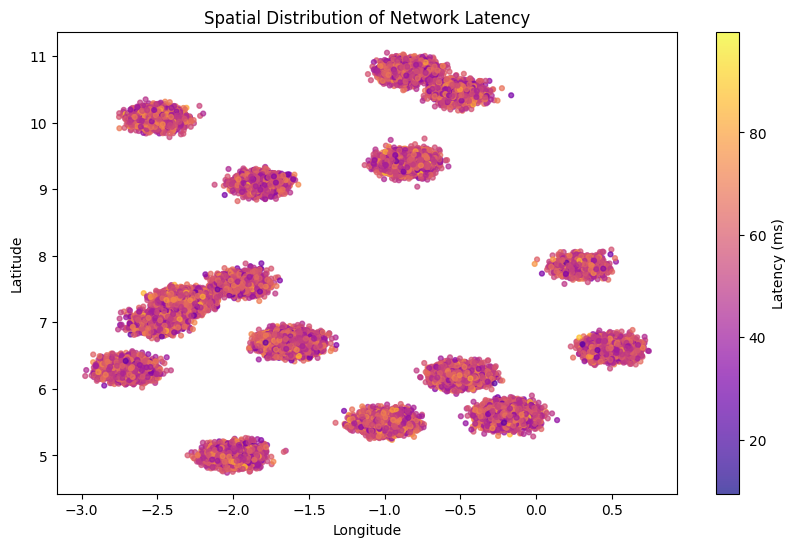

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [153]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

points = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["latency_ms"],
    cmap="plasma",
    s=12,
    alpha=0.7
)

plt.colorbar(points, label="Latency (ms)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Network Latency")
plt.show()

In [154]:
urban_comparison = (
    df.groupby("urban_rural")
    .agg(
        observations=("record_id", "count"),
        avg_latency=("latency_ms", "mean"),
        avg_download=("avg_download_mbps", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_availability=("network_availability_pct", "mean")
    )
    .round(2)
)

urban_comparison

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,observations,avg_latency,avg_download,avg_packet_loss,avg_availability
urban_rural,,,,,
Rural,12273,54.79,13.88,2.3,99.00
Semi-Urban,16798,55.08,28.31,2.3,98.99
Urban,25929,54.81,47.05,2.3,99.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [155]:
daily_patterns = (
    df.groupby("day_of_week")
    .agg(
        observations=("record_id", "count"),
        avg_latency=("latency_ms", "mean"),
        avg_download=("avg_download_mbps", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_congestion=("tower_utilization_pct", "mean"),
        total_complaints=("customer_complaints", "sum")
    )
    .round(2)
)

daily_patterns

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,observations,avg_latency,avg_download,avg_packet_loss,avg_congestion,total_complaints
day_of_week,,,,,,
Friday,7856,54.83,33.59,2.29,63.27,14109
Monday,7807,54.96,34.07,2.29,63.37,13915
Saturday,7826,54.89,33.48,2.32,63.55,14009
Sunday,7840,55.00,34.34,2.30,63.57,13775
Thursday,7942,54.87,34.14,2.31,63.58,14382
Tuesday,7881,54.83,33.98,2.30,63.47,14150
Wednesday,7848,54.85,33.87,2.30,63.26,13920


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [156]:
peak_patterns = (
    df.groupby("peak_hour")
    .agg(
        observations=("record_id", "count"),
        avg_latency=("latency_ms", "mean"),
        avg_download=("avg_download_mbps", "mean"),
        avg_utilization=("tower_utilization_pct", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_complaints=("customer_complaints", "mean")
    )
    .round(2)
)

peak_patterns

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,observations,avg_latency,avg_download,avg_utilization,avg_packet_loss,avg_complaints
peak_hour,,,,,,
False,29722,50.37,34.10,55.20,2.09,1.71
True,25278,60.21,33.72,73.13,2.54,1.88


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [157]:
peak_patterns.describe()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,observations,avg_latency,avg_download,avg_utilization,avg_packet_loss,avg_complaints
count,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
mean,27500.000000,55.290000,33.910000,64.165000,2.315000,1.795000
std,3142.382536,6.957931,0.268701,12.678425,0.318198,0.120208
min,25278.000000,50.370000,33.720000,55.200000,2.090000,1.710000
25%,26389.000000,52.830000,33.815000,59.682500,2.202500,1.752500
50%,27500.000000,55.290000,33.910000,64.165000,2.315000,1.795000
75%,28611.000000,57.750000,34.005000,68.647500,2.427500,1.837500
max,29722.000000,60.210000,34.100000,73.130000,2.540000,1.880000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [158]:
df["date"] = pd.to_datetime(df["date"])

temporal_patterns = (
    df.groupby(["date", "peak_hour"])
    .agg(
        observations=("record_id", "count"),
        avg_utilization=("tower_utilization_pct", "mean"),
        avg_latency=("latency_ms", "mean"),
        avg_download=("avg_download_mbps", "mean")
    )
    .reset_index()
)

temporal_patterns.sort_values(
    "avg_utilization",
    ascending=False
).head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,date,peak_hour,observations,avg_utilization,avg_latency,avg_download
517,2025-09-16,True,65,76.984769,60.206462,30.689231
529,2025-09-22,True,74,76.092973,62.617027,27.583378
563,2025-10-09,True,79,75.881266,62.495696,40.478101
53,2025-01-27,True,67,75.676418,61.400896,37.449701
557,2025-10-06,True,63,75.631905,61.328571,28.326190
465,2025-08-21,True,65,75.573077,60.439077,42.150923
167,2025-03-25,True,70,75.560143,60.216000,34.610429
189,2025-04-05,True,57,75.492632,60.036140,35.915965
461,2025-08-19,True,76,75.414474,61.513289,40.852500
549,2025-10-02,True,64,75.410781,61.205937,22.756875


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

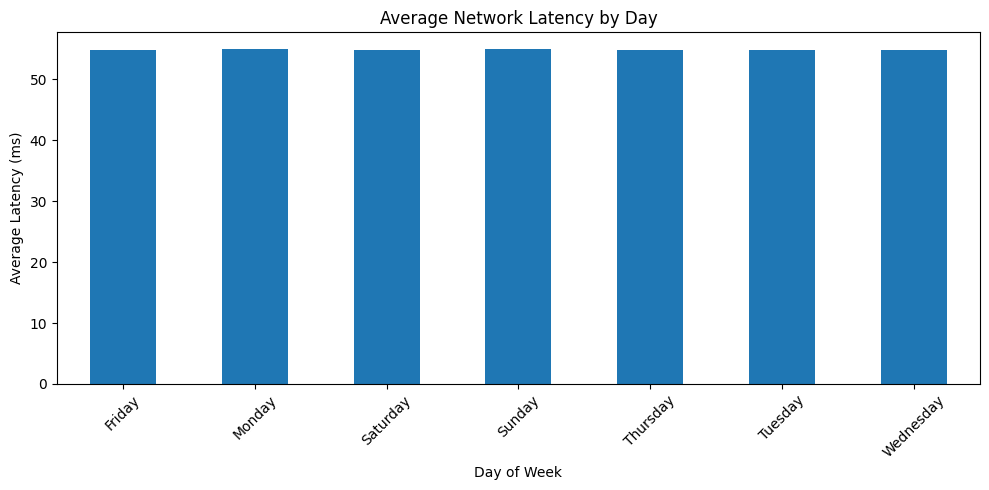

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [159]:
import matplotlib.pyplot as plt

daily_plot = (
    df.groupby("day_of_week")["latency_ms"]
    .mean()
)

daily_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Average Network Latency by Day")
plt.xlabel("Day of Week")
plt.ylabel("Average Latency (ms)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [160]:
df_time = df.sort_values(
    ["site_id", "date", "time"]
).copy()

df_time["high_congestion"] = (
    df_time["congestion_level"] == "High"
)

df_time["poor_performance"] = (
    df_time["network_performance_score"] == "Low"
)

df_time["next_poor_performance"] = (
    df_time.groupby("site_id")["poor_performance"]
    .shift(-1)
)

congestion_followed_by_poor = (
    df_time[df_time["high_congestion"]]["next_poor_performance"]
    .mean()
)

baseline_poor_performance = (
    df_time["next_poor_performance"].mean()
)

print("Poor performance after high congestion:",
      round(congestion_followed_by_poor * 100, 2), "%")

print("Overall next-observation poor performance rate:",
      round(baseline_poor_performance * 100, 2), "%")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Poor performance after high congestion: 0.0 %
Overall next-observation poor performance rate: 0.0 %


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [161]:
rare_events = pd.DataFrame({
    "high_churn_risk": df["churn_risk"] == "High",
    "severe_packet_loss": df["packet_loss_pct"] >= 5,
    "low_availability": df["network_availability_pct"] < 95,
    "high_complaints": (
        df["customer_complaints"] >
        df["customer_complaints"].quantile(0.95)
    ),
    "low_download_speed": (
        df["avg_download_mbps"] <
        df["avg_download_mbps"].quantile(0.05)
    )
})

rare_event_summary = pd.DataFrame({
    "event_count": rare_events.sum(),
    "event_rate_pct": rare_events.mean() * 100
}).round(2)

rare_event_summary.sort_values("event_rate_pct")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,event_count,event_rate_pct
low_availability,1,0.00
high_churn_risk,818,1.49
severe_packet_loss,981,1.78
low_download_speed,1987,3.61
high_complaints,2297,4.18


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [162]:
df["severe_network_event"] = (
    (df["packet_loss_pct"] >= 5) &
    (df["network_availability_pct"] < 95) &
    (df["avg_download_mbps"] <
     df["avg_download_mbps"].quantile(0.05))
)

print("Severe combined events:", df["severe_network_event"].sum())

print(
    "Percentage of observations:",
    round(df["severe_network_event"].mean() * 100, 3)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Severe combined events: 0
Percentage of observations: 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [163]:
site_rare_events = (
    df.groupby("site_id")
    .agg(
        total_observations=("record_id", "count"),
        severe_events=("severe_network_event", "sum"),
        avg_latency=("latency_ms", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_availability=("network_availability_pct", "mean")
    )
    .reset_index()
)

site_rare_events["severe_event_rate_pct"] = (
    site_rare_events["severe_events"] /
    site_rare_events["total_observations"] * 100
)

site_rare_events.sort_values(
    "severe_event_rate_pct",
    ascending=False
).head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,site_id,total_observations,severe_events,avg_latency,avg_packet_loss,avg_availability,severe_event_rate_pct
8978,SITE-09998,7,0,59.004286,2.229429,98.960000,0.0
0,SITE-01000,5,0,57.520000,2.153200,99.096000,0.0
1,SITE-01001,13,0,55.826154,2.272000,99.165385,0.0
8962,SITE-09982,5,0,57.474000,1.940600,99.002000,0.0
8961,SITE-09981,13,0,46.937692,2.315462,98.788462,0.0
8960,SITE-09980,7,0,54.222857,2.380714,99.145714,0.0
8959,SITE-09979,5,0,52.378000,2.690200,99.010000,0.0
8958,SITE-09978,9,0,55.463333,2.597556,99.222222,0.0
8957,SITE-09977,4,0,47.760000,1.792000,99.035000,0.0
8956,SITE-09976,6,0,52.060000,1.779000,99.191667,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [164]:
site_rare_events[
    site_rare_events["total_observations"] >= 30
].sort_values(
    "severe_event_rate_pct",
    ascending=False
).head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,site_id,total_observations,severe_events,avg_latency,avg_packet_loss,avg_availability,severe_event_rate_pct


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [165]:
high_packet_loss = df["packet_loss_pct"] >= 5
low_availability = df["network_availability_pct"] < 95

joint_rate = (high_packet_loss & low_availability).mean()
packet_loss_rate = high_packet_loss.mean()
availability_failure_rate = low_availability.mean()

print("Joint event rate:", round(joint_rate * 100, 3), "%")
print("High packet-loss rate:", round(packet_loss_rate * 100, 3), "%")
print("Low-availability rate:", round(availability_failure_rate * 100, 3), "%")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Joint event rate: 0.0 %
High packet-loss rate: 1.784 %
Low-availability rate: 0.002 %


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [166]:
threshold = df["tower_utilization_pct"].quantile(0.75)

df["high_utilization"] = (
    df["tower_utilization_pct"] >= threshold
)

df.groupby("high_utilization").agg(
    observations=("record_id", "count"),
    avg_latency=("latency_ms", "mean"),
    median_latency=("latency_ms", "median"),
    avg_download=("avg_download_mbps", "mean")
).round(2)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,observations,avg_latency,median_latency,avg_download
high_utilization,,,,
False,41248,51.74,51.82,33.99
True,13752,64.34,64.33,33.73


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [167]:
from scipy.stats import mannwhitneyu

high = df.loc[df["high_utilization"], "latency_ms"].dropna()
low = df.loc[~df["high_utilization"], "latency_ms"].dropna()

statistic, p_value = mannwhitneyu(
    high,
    low,
    alternative="two-sided"
)

print("High-utilization median:", round(high.median(), 2))
print("Lower-utilization median:", round(low.median(), 2))
print("P-value:", p_value)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

High-utilization median: 64.33
Lower-utilization median: 51.82
P-value: 0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [168]:
median_difference = high.median() - low.median()

print("Median latency difference (ms):",
      round(median_difference, 2))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Median latency difference (ms): 12.51


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [169]:
regional_validation = (
    df.groupby(["region", "high_utilization"])
    .agg(
        observations=("record_id", "count"),
        median_latency=("latency_ms", "median")
    )
    .reset_index()
)

regional_validation

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,region,high_utilization,observations,median_latency
0,Ahafo,False,1208,51.235
1,Ahafo,True,390,63.960
2,Ashanti,False,5838,51.870
3,Ashanti,True,1911,64.690
4,Bono,False,2084,51.670
5,Bono,True,726,64.755
6,Bono East,False,1637,51.860
7,Bono East,True,538,63.610
8,Central,False,2899,51.670
9,Central,True,975,64.640


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [170]:
from sklearn.model_selection import train_test_split

discovery_df, validation_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

threshold = discovery_df["tower_utilization_pct"].quantile(0.75)

for dataset in [discovery_df, validation_df]:
    dataset["high_utilization_check"] = (
        dataset["tower_utilization_pct"] >= threshold
    )

print("Discovery data:")
print(
    discovery_df.groupby("high_utilization_check")["latency_ms"]
    .median()
)

print("\nValidation data:")
print(
    validation_df.groupby("high_utilization_check")["latency_ms"]
    .median()
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Discovery data:
high_utilization_check
False    51.82
True     64.29
Name: latency_ms, dtype: float64

Validation data:
high_utilization_check
False    51.78
True     64.37
Name: latency_ms, dtype: float64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [171]:
utilization_threshold = df["tower_utilization_pct"].quantile(0.75)
latency_threshold = df["latency_ms"].quantile(0.75)
packet_loss_threshold = df["packet_loss_pct"].quantile(0.75)

df["investigation_flag"] = (
    (df["tower_utilization_pct"] >= utilization_threshold) &
    (df["latency_ms"] >= latency_threshold) &
    (df["packet_loss_pct"] >= packet_loss_threshold)
)

print("Flagged observations:", df["investigation_flag"].sum())

print(
    "Percentage flagged:",
    round(df["investigation_flag"].mean() * 100, 2),
    "%"
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Flagged observations: 3396
Percentage flagged: 6.17 %


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [172]:
df["issue_severity"] = "Normal"

df.loc[
    (df["tower_utilization_pct"] >= utilization_threshold) &
    (df["latency_ms"] >= latency_threshold),
    "issue_severity"
] = "Warning"

df.loc[
    (df["tower_utilization_pct"] >= utilization_threshold) &
    (df["latency_ms"] >= latency_threshold) &
    (df["packet_loss_pct"] >= packet_loss_threshold),
    "issue_severity"
] = "Critical"

df["issue_severity"].value_counts()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
issue_severity,
Normal,46862
Warning,4742
Critical,3396


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [173]:
operations_summary = (
    df.groupby("site_id")
    .agg(
        observations=("record_id", "count"),
        critical_events=("issue_severity",
                         lambda x: (x == "Critical").sum()),
        warning_events=("issue_severity",
                        lambda x: (x == "Warning").sum()),
        avg_latency=("latency_ms", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_utilization=("tower_utilization_pct", "mean")
    )
    .reset_index()
)

operations_summary = operations_summary.sort_values(
    ["critical_events", "avg_latency"],
    ascending=False
)

operations_summary.head(10)

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

,site_id,observations,critical_events,warning_events,avg_latency,avg_packet_loss,avg_utilization
4393,SITE-05406,9,4,1,64.830000,2.952667,77.460000
5678,SITE-06693,7,4,0,63.148571,2.738429,73.072857
2655,SITE-03666,8,4,1,60.200000,2.879750,70.520000
4823,SITE-05836,9,4,0,59.958889,2.907889,72.763333
6155,SITE-07170,12,4,0,59.894167,2.633250,66.805833
4106,SITE-05119,7,4,0,59.001429,2.841143,71.512857
5487,SITE-06501,9,4,0,58.401111,2.926222,69.924444
1616,SITE-02623,10,4,0,58.031000,2.279100,66.991000
2760,SITE-03771,13,4,0,57.794615,2.728692,70.342308
2457,SITE-03466,6,3,1,68.961667,3.401667,82.515000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Project workflow

1. Prepare the data
Check missing values, duplicates, data types, and unusual values.




2. Discover patterns
Find relationships among utilization, latency, packet loss, complaints, and churn risk.




3. Identify hotspots
Rank sites, districts, and time periods with recurring problems.




4. Validate findings
Check effect sizes, statistical evidence, sample sizes, and consistency.




5. Communicate the results
Prepare a concise findings table and recommendations for Power BI.

In [174]:
import pandas as pd
import numpy as np

# Keep the original dataframe unchanged
mining_df = df.copy()

# Check data quality
print("Rows and columns:", mining_df.shape)
print("Duplicate records:", mining_df.duplicated().sum())
print("\nMissing values:")
print(
    mining_df.isna().sum()
    .sort_values(ascending=False)
    .head(10)
)

# Check key numeric fields
key_fields = [
    "tower_utilization_pct",
    "latency_ms",
    "packet_loss_pct",
    "network_availability_pct",
    "customer_complaints"
]

print("\nDescriptive statistics:")
print(mining_df[key_fields].describe().round(2))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Rows and columns: (55000, 69)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Duplicate records: 0

Missing values:
record_id         0
date              0
time              0
region            0
district          0
cell_id           0
site_id           0
operator          0
technology        0
frequency_band    0
dtype: int64

Descriptive statistics:
       tower_utilization_pct  latency_ms  packet_loss_pct  \
count               55000.00    55000.00         55000.00   
mean                   63.44       54.89             2.30   
std                    13.32       10.84             1.00   
min                    15.14        9.41             0.00   
25%                    53.75       47.53             1.64   
50%                    63.26       54.85             2.20   
75%                    72.95       62.28             2.82   
max                   100.00       99.69             6.90   

       network_availability_pct  customer_complaints  
count                  55000.00             55000.00  
mean                      99.00                 1.79  
std      

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [175]:
util_threshold = mining_df["tower_utilization_pct"].quantile(0.75)

mining_df["high_utilization"] = (
    mining_df["tower_utilization_pct"] >= util_threshold
)

pattern_summary = (
    mining_df.groupby("high_utilization")
    .agg(
        observations=("record_id", "count"),
        avg_latency=("latency_ms", "mean"),
        median_latency=("latency_ms", "median"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_download=("avg_download_mbps", "mean")
    )
    .round(2)
)

pattern_summary

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,observations,avg_latency,median_latency,avg_packet_loss,avg_download
high_utilization,,,,,
False,41248,51.74,51.82,2.16,33.99
True,13752,64.34,64.33,2.73,33.73


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [176]:
site_summary = (
    mining_df.groupby("site_id")
    .agg(
        observations=("record_id", "count"),
        avg_latency=("latency_ms", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_availability=("network_availability_pct", "mean"),
        avg_utilization=("tower_utilization_pct", "mean"),
        total_complaints=("customer_complaints", "sum")
    )
    .reset_index()
)

# Exclude sites with too few observations
site_summary = site_summary[
    site_summary["observations"] >= 30
].copy()

site_summary.sort_values(
    ["avg_latency", "avg_packet_loss"],
    ascending=False
).head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,site_id,observations,avg_latency,avg_packet_loss,avg_availability,avg_utilization,total_complaints


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

This final table is a useful starting point for a Power BI report. The percentile thresholds are exploratory, so don't label these sites as confirmed faults without checking service standards and incident records.

In [177]:
latency_cutoff = mining_df["latency_ms"].quantile(0.75)
loss_cutoff = mining_df["packet_loss_pct"].quantile(0.75)

mining_df["performance_flag"] = (
    (mining_df["latency_ms"] >= latency_cutoff) &
    (mining_df["packet_loss_pct"] >= loss_cutoff)
)

findings = (
    mining_df.groupby("site_id")
    .agg(
        observations=("record_id", "count"),
        flagged_events=("performance_flag", "sum"),
        avg_latency=("latency_ms", "mean"),
        avg_packet_loss=("packet_loss_pct", "mean"),
        avg_availability=("network_availability_pct", "mean")
    )
    .reset_index()
)

findings = findings[
    findings["observations"] >= 30
].copy()

findings["flag_rate_pct"] = (
    findings["flagged_events"] /
    findings["observations"] * 100
)

findings = findings.sort_values(
    "flag_rate_pct",
    ascending=False
)

findings.head(10).round(2)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,site_id,observations,flagged_events,avg_latency,avg_packet_loss,avg_availability,flag_rate_pct


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [178]:
display(findings)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,site_id,observations,flagged_events,avg_latency,avg_packet_loss,avg_availability,flag_rate_pct


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag